# Exploratory hypotheses

Four questions, plots only — no API calls, no new pipeline stages. Error bars are 95%
percentile bootstrap CIs over participants; the participant is the unit of analysis, so a
participant's sessions are collapsed to one value before any group mean is taken.

| | question | section |
|---|---|---|
| **1** | Is there an immediate-vs-delayed difference for a **low-memorability** image? | §1 — aigen, `bedroom_l` only, every semantic category |
| **2** | Which objects repeat across participants, and which get **added** on attempts 2–3? | §2 — per GT image, aigen first |
| **3** | Is there a motivational aigen/nogen difference **already on trial 1**, before nogen participants know no image is coming? | §3 |
| **4** | Who are the few `plain`/perception participants inflating length and object counts? | §4 |

### Read these before the figures

**The semantic tables are stale.** 1981 rows / 192 participants, against 2101 in the current
`trials_final.csv` — and the two participants added on 2026-08-18 are in neither. Stages 6–7
(`semantic_tagging.py`, `object_accuracy_detector.py`, `export_full_data.py`) have not been
re-run. Nothing below needs editing once they are; just re-execute.

**Objects are free-form strings.** The tagger writes what it sees, so the same object arrives
as `pillows` / `pillow`, `wooden bench` / `bench`, `bedpost` / `bed post`. Counted raw, those
participants *disagree* purely on wording. §0.1 builds a normalized view that fixes spelling,
plurals and descriptive modifiers — but it does **not** merge parts into wholes: `bed post`,
`headboard` and `bed` stay three separate objects, because a participant who reported the posts
of the four-poster reported something different from one who reported the bed.

**Every §2 analysis is produced twice** — once normalized, once on the raw tagger strings —
with the mode in the figure title and filename. The gap between the two is the measurement of
how much wording alone moves the answer, and neither is privileged.

In [1]:
import sys
import json
import itertools
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap

sys.path.insert(0, str(Path.cwd() if (Path.cwd() / "plot_helpers.py").exists()
                       else Path.cwd() / "analysis" / "notebooks"))
from plot_helpers import *          # noqa: F403

config = import_config()
set_style()
print("project root:", config.ROOT)

project root: /mnt/hdd/anatkorol/Imagination_in_translation


## Load

In [2]:
COUNT_MODE = "validated"
FULL = config.ROOT / "Data" / "processed_data" / "Full_experiment" / "combined" / "full_data"
GRAPHS = config.COMBINED_ANALYSIS_DIR / "graphs" / "exploratory_hypotheses"
GRAPHS.mkdir(parents=True, exist_ok=True)

df = prep_counts(pd.read_csv(FULL / "trials_final_semantic_tag_image_validation_full_data.csv"),
                 "trials", mode=COUNT_MODE)

sim = pd.read_csv(FULL / "trials_final_sim_full_data.csv")
df = df.merge(sim[["uid", "session", "attempt", "token_num", "clip_cosine_distance",
                   "vgg_fc7_distance"]],
              on=["uid", "session", "attempt"], how="left", validate="1:1")
df["clip_similarity"] = 1 - df["clip_cosine_distance"]

ceil = load_gpt_ceiling(config, mode=COUNT_MODE)
items = explode_items(df)
objs = items[items["category"] == "objects"].copy()

BEDROOM = "bedroom_l.jpg"
GT_ORDER = ["bedroom_l.jpg", "living_room_h.jpg", "conference_room_h.jpg",
            "lighthouse_h.jpg", "playground_h.jpg"]
GT_LABELS = {g: g.replace(".jpg", "") for g in GT_ORDER}
GEN_ORDER = ["aigen", "nogen", "plain"]
FB_GENS = ["aigen", "nogen"]

print(f"\nrows={len(df)}  participants={df['uid'].nunique()}  "
      f"validation errors={int(df['error'].notna().sum())}")
assert len(items) == df["n_extracted"].sum(), "explode lost or duplicated items"
print(f"objects: {len(objs)} tags, {objs['item'].nunique()} distinct raw strings")

loaded gpt-5.5_desc from gpt_ceiling/: 5 descriptions, 5 GT images
exploded items: 34525 rows, 8789 distinct item strings

rows=1981  participants=192  validation errors=0
objects: 13967 tags, 1591 distinct raw strings


## 0.1 Normalizing the object strings

Four passes. Everything is **printed in full** — this is a judgement call, not a measurement,
and it should be argued with rather than trusted.

1. **Lemma** — lowercase, drop leading articles, strip possessives, naive singularization
   (with an exception list so `glass` / `grass` / `mattress` survive).
2. **Synonym map** (hand-written, highest priority) — `carpet` → `rug`, `painting` → `picture`,
   `bedpost` → `bed post`. Same object, different word or spelling.
3. **Part guard** — a string whose head word names a *part* (`post`, `frame`, `seat`, `head`,
   `leg`, …) is **left exactly as it is**. This is what keeps `bed post` out of `bed` and
   `chair seat` out of `chair`.
4. **Head-noun fallback** — a multiword lemma whose last word is a common standalone object
   collapses onto it, stripping a purely descriptive modifier: `wooden bench` → `bench`,
   `back wall` → `wall`, `left hand side wall` → `wall`.

### Two rules the map obeys

- **A part is never merged into its whole.** `bed`, `bed post`, `headboard`, `footboard` and
  `bed frame` are five objects, not one. Merging them would manufacture agreement that is not
  in the data — a participant naming the posts saw and reported something specific.
- **Two things that might differ are never merged.** `stool` / `bench`, `tree` / `plant`,
  `magazine` / `book`, `dresser` / `wardrobe`, `jar` / `vase`, `cushion` / `pillow` are all
  left alone, even though the tagger uses them loosely.

`item` is the raw string, `item_norm` the normalized one; `NORM_MODES` holds both and every
§2 cell loops over it.

In [3]:
ARTICLES = re.compile(r"^(a|an|the|some|several|two|three|four|five)\s+")
KEEP_S = {"glass", "grass", "mattress", "brass", "class", "cross", "dress", "press", "moss",
          "stairs", "scissors", "shelves", "leaves", "blinds", "shorts", "curtains", "jeans",
          "headphones", "glasses", "trousers", "surroundings", "bushes", "clothes"}
IRREGULAR = {"leaves": "leaf", "shelves": "shelf", "people": "person", "feet": "foot",
             "benches": "bench", "bushes": "bush", "boxes": "box", "couches": "couch",
             "dishes": "dish", "glasses": "glass", "vases": "vase", "arches": "arch"}


def lemma(s):
    """Pass 1: lowercase, drop articles/possessives, singularize."""
    s = str(s).strip().lower()
    s = ARTICLES.sub("", s)
    s = s.replace("'s ", " ").replace("’s ", " ").strip()
    if s in IRREGULAR:
        return IRREGULAR[s]
    if s.endswith("s") and not s.endswith("ss") and s not in KEEP_S and len(s) > 3:
        return s[:-1]
    return s


# Pass 2 - the merges no rule can infer. Canonical form <- strings that mean the SAME THING.
#
# Two rules govern what may go in here, both learned the hard way:
#   1. NEVER merge a PART into its WHOLE. "bed post" is not "bed" - a participant who reports
#      the posts of the four-poster has reported a different object from one who reports the
#      bed, and collapsing them invents agreement that is not in the data. Parts get their own
#      canonical entry below, so only their SPELLINGS are unified.
#   2. NEVER merge two things that could be different objects. stool / bench, tree / plant,
#      magazine / book, dresser / wardrobe, jar / vase, cushion / pillow are all plausibly
#      distinct and are left alone, even though the tagger often uses them loosely.
# What is left is genuine synonymy and spelling variance.
CONCEPT_MAP = {
    # --- whole objects: the same thing under another name ---
    "bed": {"four-poster bed", "four poster bed", "4 poster bed", "4-post bed", "4 post bed"},
    "rug": {"carpet", "area rug", "floor rug"},
    "picture": {"painting", "artwork", "framed picture", "framed art", "framed print",
                "wall art", "photograph", "photo", "wall picture"},
    "plant": {"houseplant", "pot plant", "potted plant"},
    "nightstand": {"bedside table", "night stand"},
    "bedding": {"bedsheet", "bed sheet", "duvet", "comforter", "bedspread", "bed cover"},
    "flower": {"blossom", "floral arrangement"},
    "window": {"windowpane"},
    "wardrobe": {"armoire"},

    # --- PARTS: deliberately kept separate from the object they belong to.
    #     Only spelling variants of the SAME part are unified. ---
    "bed post": {"bedpost", "bed pole", "post of bed"},
    "headboard": {"head board", "bed head", "head of bed"},
    "footboard": {"foot board", "bed foot", "foot of bed", "bed end"},
    "bed frame": {"bedframe"},
    "lampshade": {"lamp shade"},
}

# Words that name a PART rather than a thing. A string whose head is one of these is LEFT
# ALONE: "bed post" stays "bed post", "chair seat" stays "chair seat", "bed head frame" stays
# itself. Without this the head-noun fallback below would drag every compound onto its final
# word and merge unrelated furniture through shared parts.
PART_WORDS = {"frame", "post", "head", "foot", "end", "leg", "base", "handle", "header",
              "seat", "arm", "edge", "side", "corner", "back", "top", "bottom", "surface",
              "panel", "rail", "board", "cover", "sheet", "shade", "light", "knob", "drawer",
              "cushion", "pole", "slat", "rung", "step"}

# Tagger artifacts: not objects at all. Dropped from the object analyses, and the count of
# what was dropped is printed so the decision stays visible.
NOT_OBJECTS = {"corner", "background", "foreground", "side", "edge", "top", "bottom", "middle",
               "center", "centre", "area", "space", "scene", "room", "view", "part", "section",
               "left", "right", "front", "back"}

_TO_CONCEPT = {v: k for k, vs in CONCEPT_MAP.items() for v in vs}

In [4]:
# Pass 3 needs to know which single words are common enough to absorb their modifiers.
objs["item_lemma"] = objs["item"].map(lemma)
_single = objs.loc[~objs["item_lemma"].str.contains(" "), "item_lemma"]
COMMON_HEADS = set(_single.value_counts()[lambda s: s >= 20].index) - NOT_OBJECTS


def normalize(s):
    """lemma -> synonym map -> part-word guard -> head-noun fallback.

    The part-word guard is what keeps "bed post" distinct from "bed": it returns the string
    untouched rather than letting the head-noun fallback collapse it.
    """
    x = lemma(s)
    if x in _TO_CONCEPT:            # pass 2 wins outright
        return _TO_CONCEPT[x]
    if " " in x:
        words = x.split()
        head = words[-1]
        if head in PART_WORDS:      # "<object> <part>": a part, keep as its own object
            return x
        # "<part> of <object>" puts the WHOLE in head position ("base of bed"), so the head
        # test above misses it and the fallback below would merge the part into the object.
        if " of " in x and words[0] in PART_WORDS:
            return x
        if head in COMMON_HEADS:    # descriptive modifier only: "wooden bench" -> "bench"
            return head
    return x


objs["item_norm"] = objs["item_lemma"].map(normalize)

# What the normalization actually did, so it can be checked rather than believed.
n_raw, n_lem, n_norm = (objs["item"].nunique(), objs["item_lemma"].nunique(),
                        objs["item_norm"].nunique())
print(f"distinct object strings: raw {n_raw}  ->  lemma {n_lem}  ->  normalized {n_norm} "
      f"({100 * (1 - n_norm / n_raw):.0f}% fewer)")
print(f"\n{len(COMMON_HEADS)} common head nouns absorb their modifiers "
      f"(>=20 mentions as a standalone word)")

merges = (objs.groupby("item_norm")["item"].nunique().sort_values(ascending=False).head(12))
print("\nBiggest merges (normalized concept <- how many distinct raw strings):")
for concept, n in merges.items():
    raws = sorted(objs.loc[objs["item_norm"] == concept, "item"].unique())[:8]
    print(f"  {concept:14s} <- {n:3d} strings, e.g. {', '.join(raws)}")

# Confirm the part-vs-whole rule actually held, since it is the thing most likely to regress.
parts = sorted({i for i in objs["item_norm"].unique()
                if " " in i and i.split()[-1] in PART_WORDS} | set(CONCEPT_MAP) & PART_WORDS)
print(f"\nparts kept separate from their object ({len(parts)}), e.g.: "
      f"{', '.join(parts[:14])}")
for whole, part in [("bed", "bed post"), ("bed", "headboard"), ("chair", "chair seat")]:
    n_w = int((objs["item_norm"] == whole).sum())
    n_p = int((objs["item_norm"] == part).sum())
    assert not (n_p and objs.loc[objs["item_norm"] == part, "item"].isin([whole]).any())
    print(f"  '{whole}' = {n_w} tags, '{part}' = {n_p} tags - distinct")

dropped = objs["item_norm"].isin(NOT_OBJECTS).sum()
print(f"\ntagger artifacts flagged as non-objects: {dropped} tags "
      f"({100 * dropped / len(objs):.1f}%) - excluded from §2 by OBJ = objs_clean")
objs_clean = objs[~objs["item_norm"].isin(NOT_OBJECTS)].copy()

distinct object strings: raw 1591  ->  lemma 1585  ->  normalized 1142 (28% fewer)

79 common head nouns absorb their modifiers (>=20 mentions as a standalone word)

Biggest merges (normalized concept <- how many distinct raw strings):
  table          <-  32 strings, e.g. bench like table, center table, centre table, coffee table, conference glass table, conference table, dining room table, end table
  chair          <-  19 strings, e.g. accent chair, arm chair, bed chair, chair, conference chair, cushion chair, desk chair, dining chair
  structure      <-  19 strings, e.g. brown structure, children's play structure, circular structure, climbing structure, cupola-like structure, green structure, house like structure, inflatable play structure
  window         <-  18 strings, e.g. arch glass window, arch window, arched window, bay window, fanlight window, floor to ceiling window, glass window, half arch window
  wall           <-  17 strings, e.g. adjoining wall, back wall, black plast

In [5]:
# The frame every §2 figure reads, and the two string columns it can be read through.
# Every §2 figure is produced twice, once per mode, with the mode in the filename.
OBJ = objs_clean
NORM = "item_norm"
NORM_MODES = ("item_norm", "item")
NORM_LABEL = {"item": "raw strings", "item_norm": "normalized"}

print("participants per GT x task (attempt 1), aigen:")
display(df[(df["generation"] == "aigen") & (df["attempt"] == 1)]
        .pivot_table(index="gt", columns="task", values="uid", aggfunc="nunique"))

participants per GT x task (attempt 1), aigen:


task,delay,immediate,perception
gt,,,
bedroom_l.jpg,21,21,19
conference_room_h.jpg,21,23,19
lighthouse_h.jpg,19,21,18
living_room_h.jpg,20,22,19
playground_h.jpg,18,22,18


---
# 1. Is there an immediate-vs-delayed difference for a low-memorability image?

`bedroom_l` is the only low-memorability GT (`_l`); the other four are `_h`. If the null
immediate-vs-delayed result across the whole set is a floor effect — four images too memorable
for a few minutes' delay to cost anything — then the delay should bite here and nowhere else.

**aigen only, `bedroom_l` only, all three tasks, all three attempts, every semantic category.**
N is 19 / 21 / 21 participants (perception / immediate / delayed), so participant dots are
drawn on every bar: the sample size should be visible in the figure, not stated beside it.

The dashed line is **`bedroom_l`'s own GPT ceiling** — what the tagger extracts from a
description written while looking at *this* image — not the five-image average.

> One image, one arm. Treat anything here as a reason to run more low-memorability images.

bedroom_l / aigen — participants per task:


task
delay         21
immediate     21
perception    19
Name: participants, dtype: int64

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s1_bedroom_aigen_all_categories.png


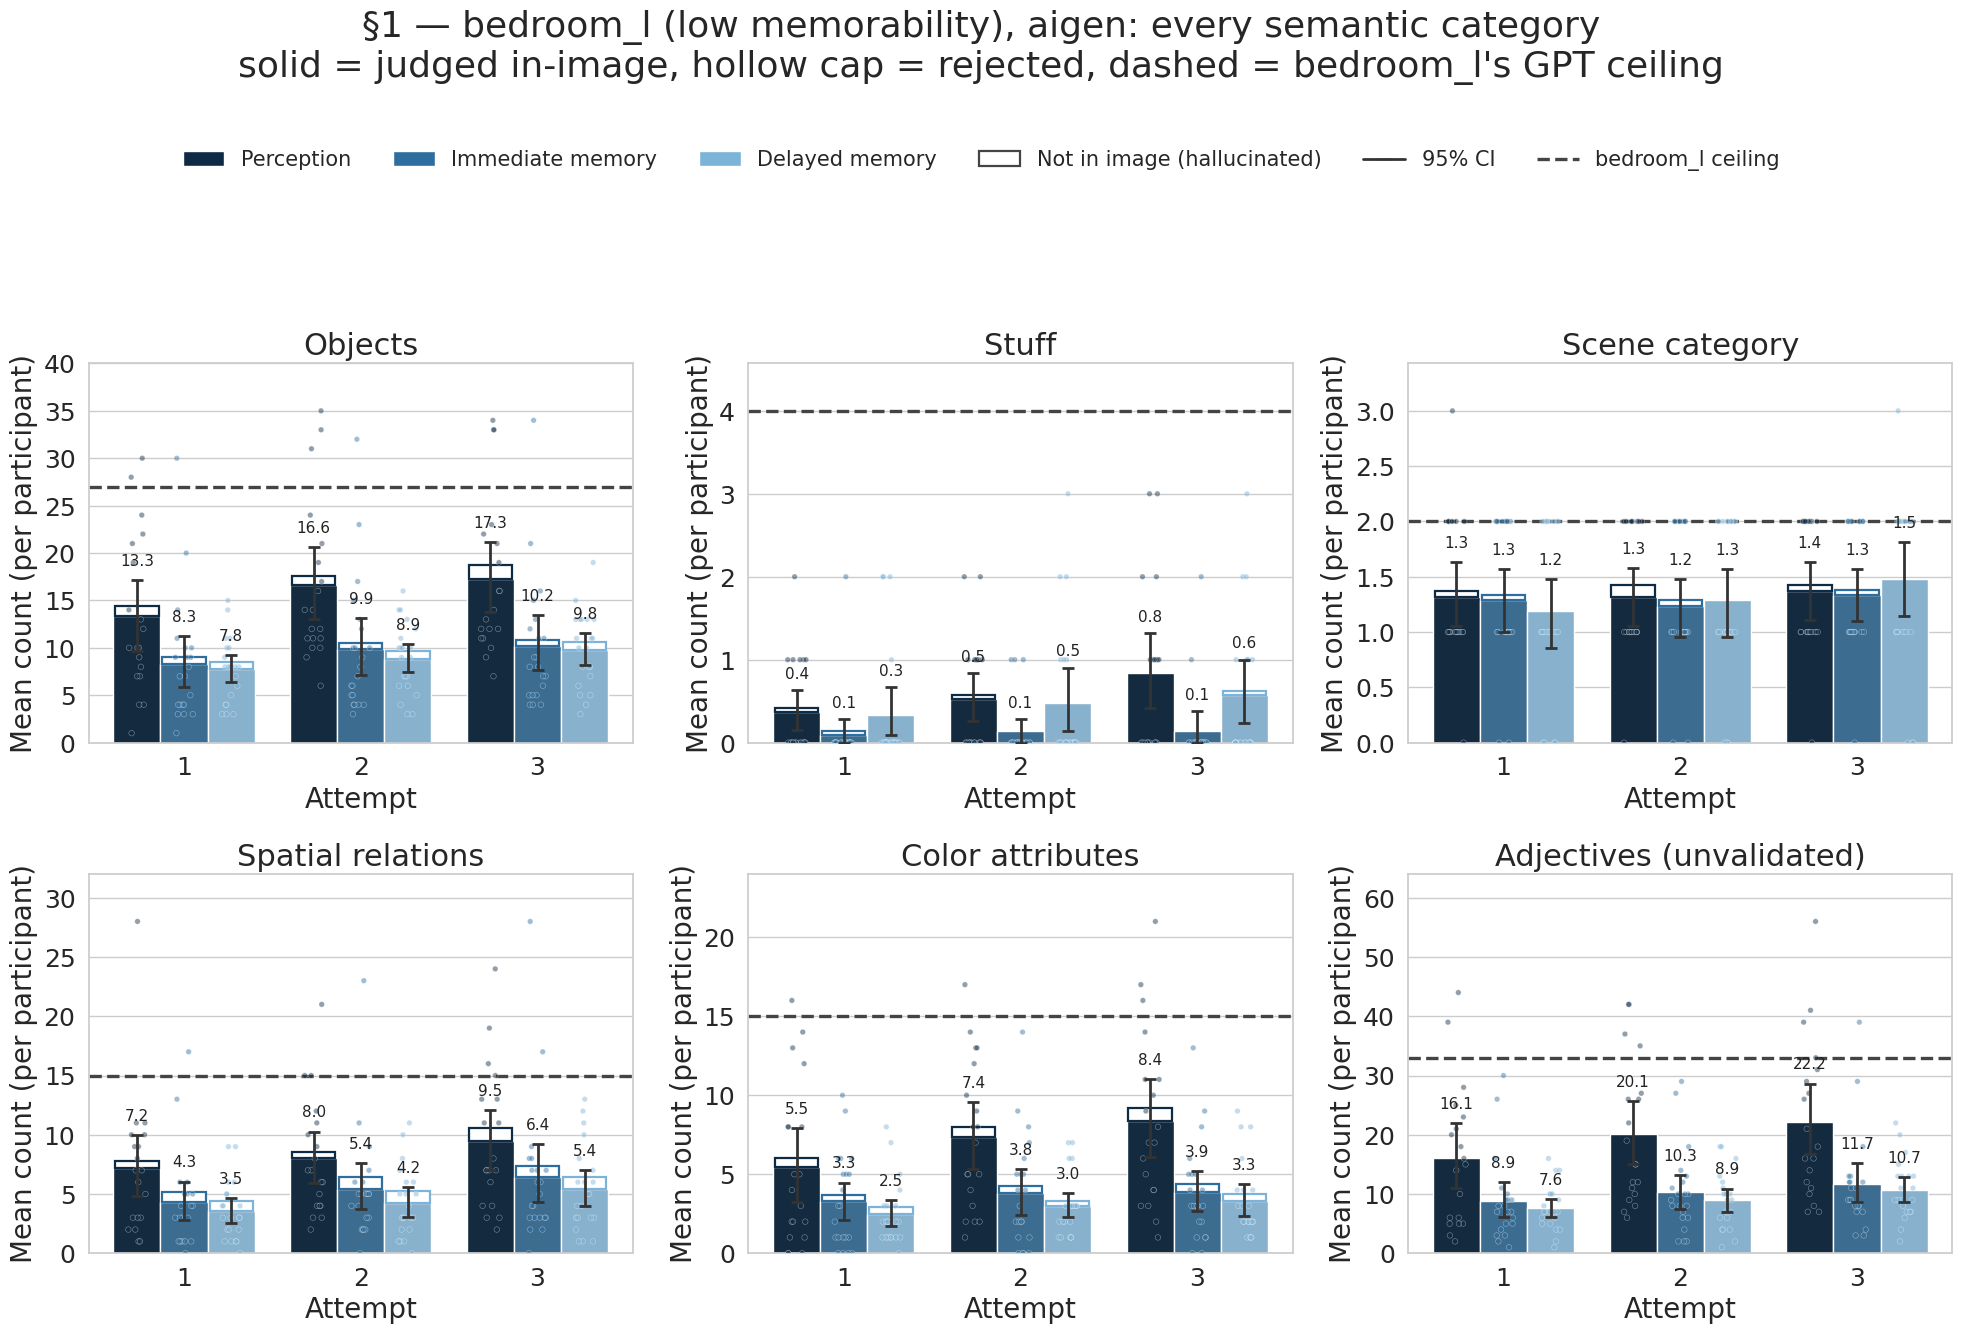

In [6]:
BED = df[(df["gt"] == BEDROOM) & (df["generation"] == "aigen")].copy()
bed_ceil = ceil[ceil["gt"] == BEDROOM].iloc[0] if ceil is not None else None

print("bedroom_l / aigen — participants per task:")
display(BED[BED["attempt"] == 1].groupby("task")["uid"].nunique().rename("participants"))

fig, axes = plt.subplots(2, 3, figsize=(20, 13.5))
for ax, cat in zip(axes.ravel(), CATEGORIES):
    ppt = ppt_means(BED, ["task", "uid", "attempt"], cat)
    vmax = draw_bars(ax, ppt, "attempt", ATTEMPTS, "task", TASK_ORDER, "count",
                     cap_col="cap" if is_validated(cat, COUNT_MODE) else None,
                     palette=TASK_COLORS, fmt="{:.1f}")
    if bed_ceil is not None:
        ax.axhline(bed_ceil[f"n_{cat}"], color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
        vmax = max(vmax, bed_ceil[f"n_{cat}"] * 1.09)
    ax.set_title(cat_label(cat, COUNT_MODE))
    ax.set_xlabel("Attempt"); ax.set_ylabel("Mean count (per participant)")
    style_count_axis(ax, vmax=vmax)

fig.suptitle("§1 — bedroom_l (low memorability), aigen: every semantic category\n"
             "solid = judged in-image, hollow cap = rejected, dashed = bedroom_l's GPT ceiling",
             y=0.995)
handles = [Patch(facecolor=TASK_COLORS[t], label=TASK_LABELS[t]) for t in TASK_ORDER]
handles += [Patch(facecolor=CAP_FACE, edgecolor="#444444", linewidth=CAP_LW, label=CAP_LABEL),
            Line2D([], [], color=CI_COLOR, lw=2, marker="_", markersize=10, label="95% CI"),
            Line2D([], [], color=GPT_DESC_COLOR, lw=2.4, ls="--", label="bedroom_l ceiling")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.905),
           ncol=len(handles), frameon=False, fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.855))
save_fig(fig, GRAPHS / "s1_bedroom_aigen_all_categories.png")
plt.show()

### 1.1 The same picture for the other four images, side by side

Every category twice: **`bedroom_l` on the left, the four high-memorability images on the
right**, sharing a y axis so the heights are directly comparable. Each panel carries its own
ceiling line — `bedroom_l`'s own on the left, the mean of the other four on the right — because
the scenes differ in how much there is to describe.

**This comparison is paired.** Every aigen participant saw all five images across their five
sessions, so the same people appear in both panels of a pair; the "other 4" bars are each
participant's mean over their four non-bedroom sessions, taken before the group mean. That
makes this a stronger contrast than the immediate-vs-delayed one in §1.2, which is between
participants.

What to look for: the memory bars collapsing toward each other on the **right** (the floor
effect the whole question is about) while staying apart on the **left**.

In [7]:
OTHERS = df[(df["generation"] == "aigen") & (df["gt"] != BEDROOM)].copy()
OTH_CEIL = ({c: ceil[ceil["gt"] != BEDROOM][f"n_{c}"].mean() for c in CATEGORIES}
            if ceil is not None else {})

IMG_SLICES = [("bedroom_l  (LOW memorability)", BED,
               lambda c: bed_ceil[f"n_{c}"] if bed_ceil is not None else None),
              ("other 4 images  (high memorability)", OTHERS,
               lambda c: OTH_CEIL.get(c))]


def _pair_panels(cat, ax_left, ax_right, ylabel=True):
    """Draw one category into an adjacent (bedroom, others) pair on a shared y scale.

    ppt_means keys on uid, so on the right each participant is collapsed over their four
    non-bedroom sessions FIRST - otherwise the right panel would be a mean over trials and the
    left a mean over people, and the two bars would not be the same kind of number.
    """
    vmaxes = []
    for ax, (label, data, cref) in zip((ax_left, ax_right), IMG_SLICES):
        ppt = ppt_means(data, ["task", "uid", "attempt"], cat)
        v = draw_bars(ax, ppt, "attempt", ATTEMPTS, "task", TASK_ORDER, "count",
                      cap_col="cap" if is_validated(cat, COUNT_MODE) else None,
                      palette=TASK_COLORS, fmt="{:.1f}")
        ref = cref(cat)
        if ref is not None and not np.isnan(ref):
            ax.axhline(ref, color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
            v = max(v, ref * 1.09)
        vmaxes.append(v)
        low = data is BED
        ax.set_title(f"{cat_label(cat, COUNT_MODE)}\n{label}", fontsize=17,
                     color="#c0392b" if low else "#333333")
        ax.set_xlabel("Attempt")
        ax.set_ylabel("Mean count (per participant)" if ylabel and low else "")
        if low:                       # frame the panel the hypothesis is about
            for sp in ax.spines.values():
                sp.set(visible=True, color="#c0392b", linewidth=3)
    for ax in (ax_left, ax_right):    # one scale across the pair, or the comparison is fake
        style_count_axis(ax, vmax=max(vmaxes))


PAIR_LEGEND = ([Patch(facecolor=TASK_COLORS[t], label=TASK_LABELS[t]) for t in TASK_ORDER]
               + [Patch(facecolor=CAP_FACE, edgecolor="#444444", linewidth=CAP_LW,
                        label=CAP_LABEL),
                  Line2D([], [], color=CI_COLOR, lw=2, marker="_", markersize=10,
                         label="95% CI"),
                  Line2D([], [], color=GPT_DESC_COLOR, lw=2.4, ls="--",
                         label="that panel's GPT ceiling")])

print("participants contributing to each side (attempt 1):")
display(pd.DataFrame({
    "bedroom_l": BED[BED["attempt"] == 1].groupby("task")["uid"].nunique(),
    "other 4": OTHERS[OTHERS["attempt"] == 1].groupby("task")["uid"].nunique()}))

participants contributing to each side (attempt 1):


,bedroom_l,other 4
task,,
delay,21,23
immediate,21,23
perception,19,20


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s1_bedroom_vs_others_all_categories.png


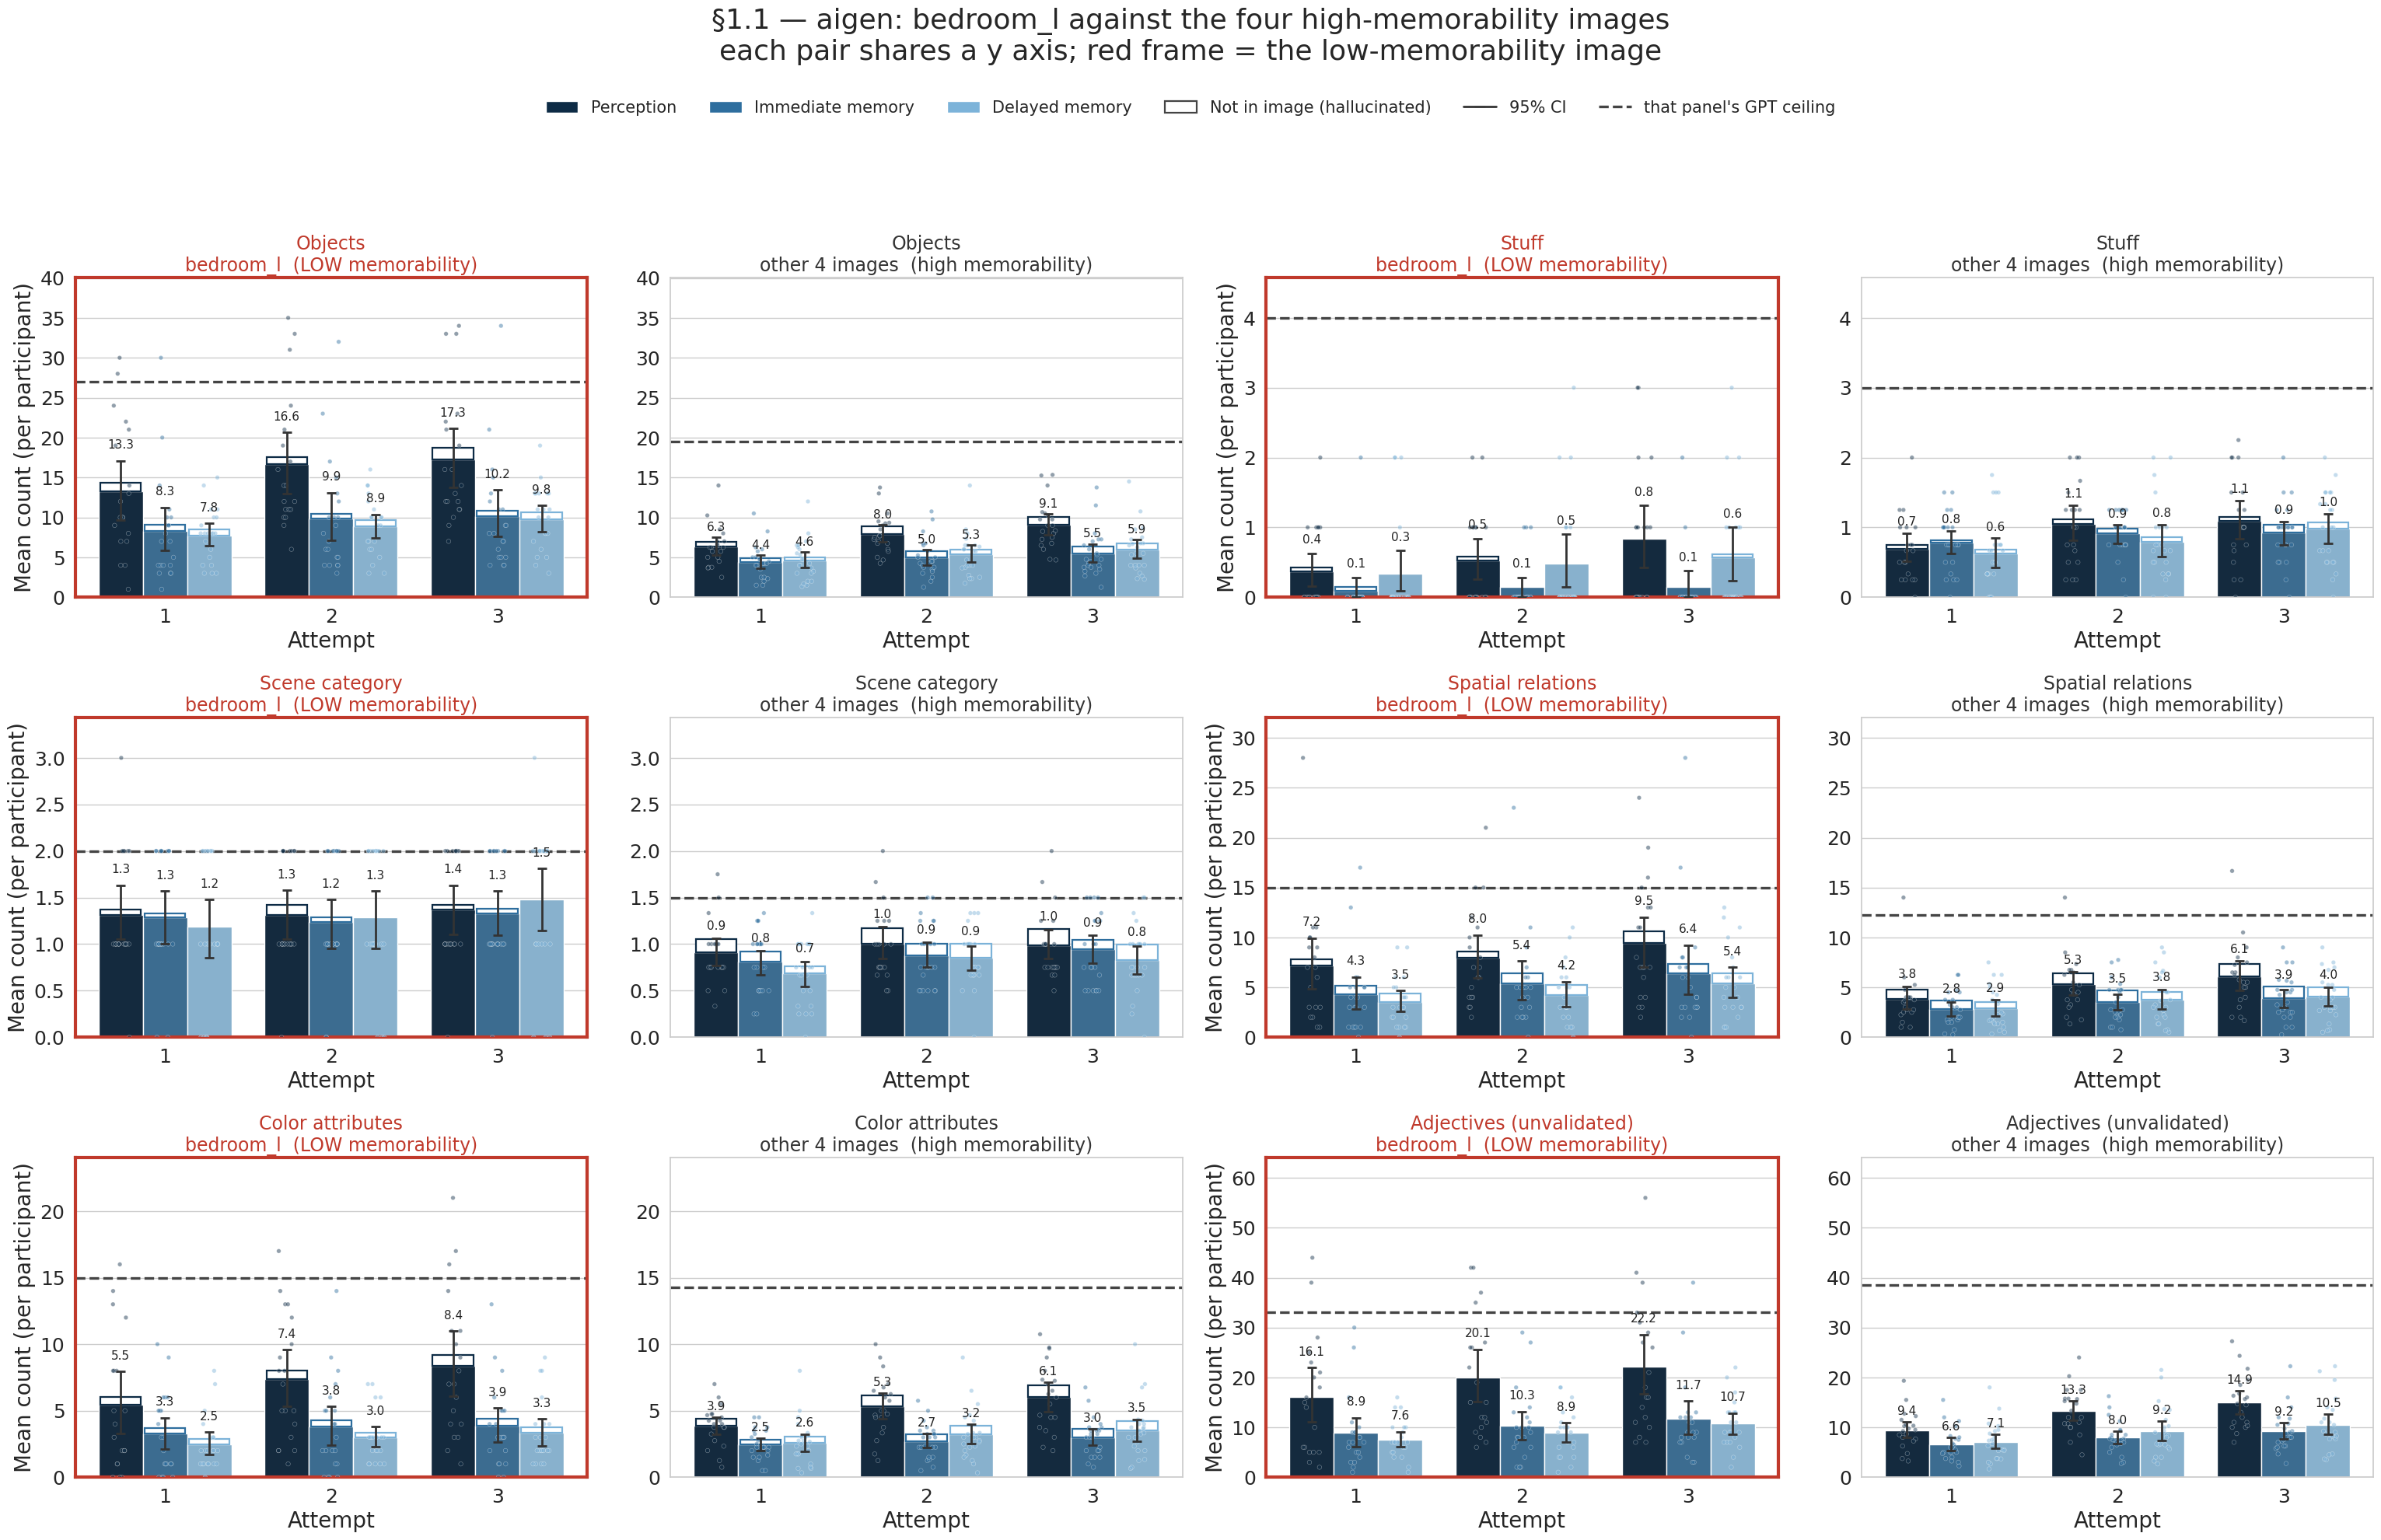

In [8]:
# All six categories at once: each category occupies an adjacent (bedroom | others) pair.
fig, axes = plt.subplots(3, 4, figsize=(31, 20))
for k, cat in enumerate(CATEGORIES):
    r, c = divmod(k, 2)
    _pair_panels(cat, axes[r, c * 2], axes[r, c * 2 + 1])
fig.suptitle("§1.1 — aigen: bedroom_l against the four high-memorability images\n"
             "each pair shares a y axis; red frame = the low-memorability image", y=0.995)
fig.legend(handles=PAIR_LEGEND, loc="upper center", bbox_to_anchor=(0.5, 0.945),
           ncol=len(PAIR_LEGEND), frameon=False, fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.915))
save_fig(fig, GRAPHS / "s1_bedroom_vs_others_all_categories.png")
plt.show()

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s1_bedroom_vs_others_objects.png


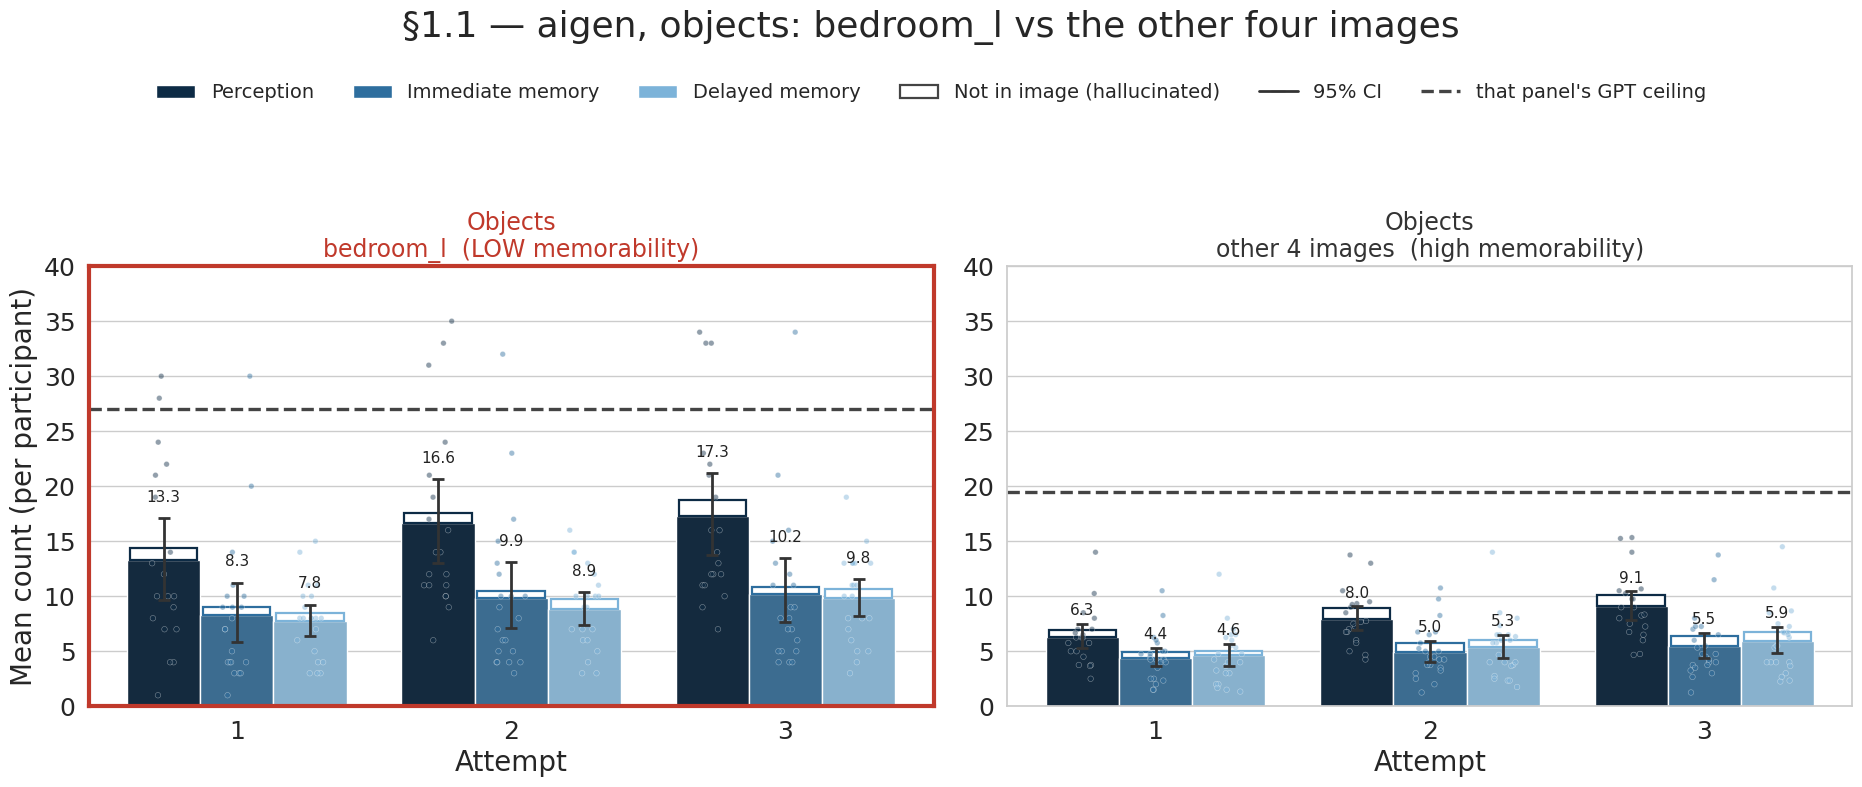

In [9]:
# Objects on its own, full size - the category the question is really about.
for cat in ["objects"]:
    fig, axes = plt.subplots(1, 2, figsize=(19, 8))
    _pair_panels(cat, axes[0], axes[1])
    fig.suptitle(f"§1.1 — aigen, {CATEGORIES[cat].lower()}: bedroom_l vs the other four images",
                 y=0.995)
    fig.legend(handles=PAIR_LEGEND, loc="upper center", bbox_to_anchor=(0.5, 0.925),
               ncol=len(PAIR_LEGEND), frameon=False, fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    save_fig(fig, GRAPHS / f"s1_bedroom_vs_others_{cat}.png")
    plt.show()

### 1.2 The immediate → delayed gap, as a number

The figure above shows three tasks; the hypothesis is only about the **second segment**. Below
is immediate minus delayed for every category and attempt, with a bootstrap CI on the
difference of the two independent group means (task is between-participants, so this cannot be
paired). A CI containing zero is the same null as the full-set analysis — just measured on the
one image where it was predicted not to hold.

For contrast, the same quantity computed on the four high-memorability images is shown
alongside. The hypothesis predicts the `bedroom_l` gap to be the larger of the two.

In [10]:
def imm_del_gap(data, cat, attempt, n_boot=2000, seed=0):
    """Mean(immediate) - mean(delayed) for one category/attempt, with a bootstrap CI."""
    ppt = ppt_means(data[data["attempt"] == attempt], ["task", "uid"], cat)
    a = ppt[ppt["task"] == "immediate"]["count"].to_numpy()
    b = ppt[ppt["task"] == "delay"]["count"].to_numpy()
    if len(a) < 3 or len(b) < 3:
        return None
    rng = np.random.default_rng(seed)
    boots = [rng.choice(a, len(a), True).mean() - rng.choice(b, len(b), True).mean()
             for _ in range(n_boot)]
    return {"immediate": a.mean(), "delayed": b.mean(), "gap": a.mean() - b.mean(),
            "lo": np.percentile(boots, 2.5), "hi": np.percentile(boots, 97.5),
            "n_imm": len(a), "n_del": len(b)}


AIGEN = df[df["generation"] == "aigen"]
HIGH = AIGEN[AIGEN["gt"] != BEDROOM]
rows = []
for label, data in [("bedroom_l (low)", BED), ("other 4 (high)", HIGH)]:
    for cat in CATEGORIES:
        for att in ATTEMPTS:
            r = imm_del_gap(data, cat, att)
            if r:
                rows.append({"images": label, "category": cat, "attempt": att, **r})
gaps = pd.DataFrame(rows)
gaps["excludes_0"] = ~((gaps["lo"] <= 0) & (0 <= gaps["hi"]))

print("Immediate minus delayed (positive = delayed is worse):")
display(gaps.pivot_table(index=["category", "attempt"], columns="images",
                         values="gap").round(2))
print(f"\nintervals excluding zero: "
      f"{gaps.groupby('images')['excludes_0'].sum().to_dict()} of {len(gaps) // 2} each")

Immediate minus delayed (positive = delayed is worse):


images                     bedroom_l (low)  other 4 (high)
category          attempt                                 
adjectives        1                   1.29           -0.49
                  2                   1.38           -1.18
                  3                   0.95           -1.34
attr_color        1                   0.81           -0.07
                  2                   0.81           -0.47
                  3                   0.52           -0.50
objects           1                   0.57           -0.20
                  2                   1.00           -0.38
                  3                   0.38           -0.47
scene_category    1                   0.10            0.12
                  2                  -0.05            0.03
                  3                  -0.14            0.12
spatial_relations 1                   0.81           -0.08
                  2                   1.19           -0.26
                  3                   1.00           -0.13
stuff             1                  -0.24            0.16
                  2                  -0.33            0.12
                  3                  -0.43           -0.05


intervals excluding zero: {'bedroom_l (low)': 1, 'other 4 (high)': 0} of 18 each


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s1_bedroom_imm_del_gap.png


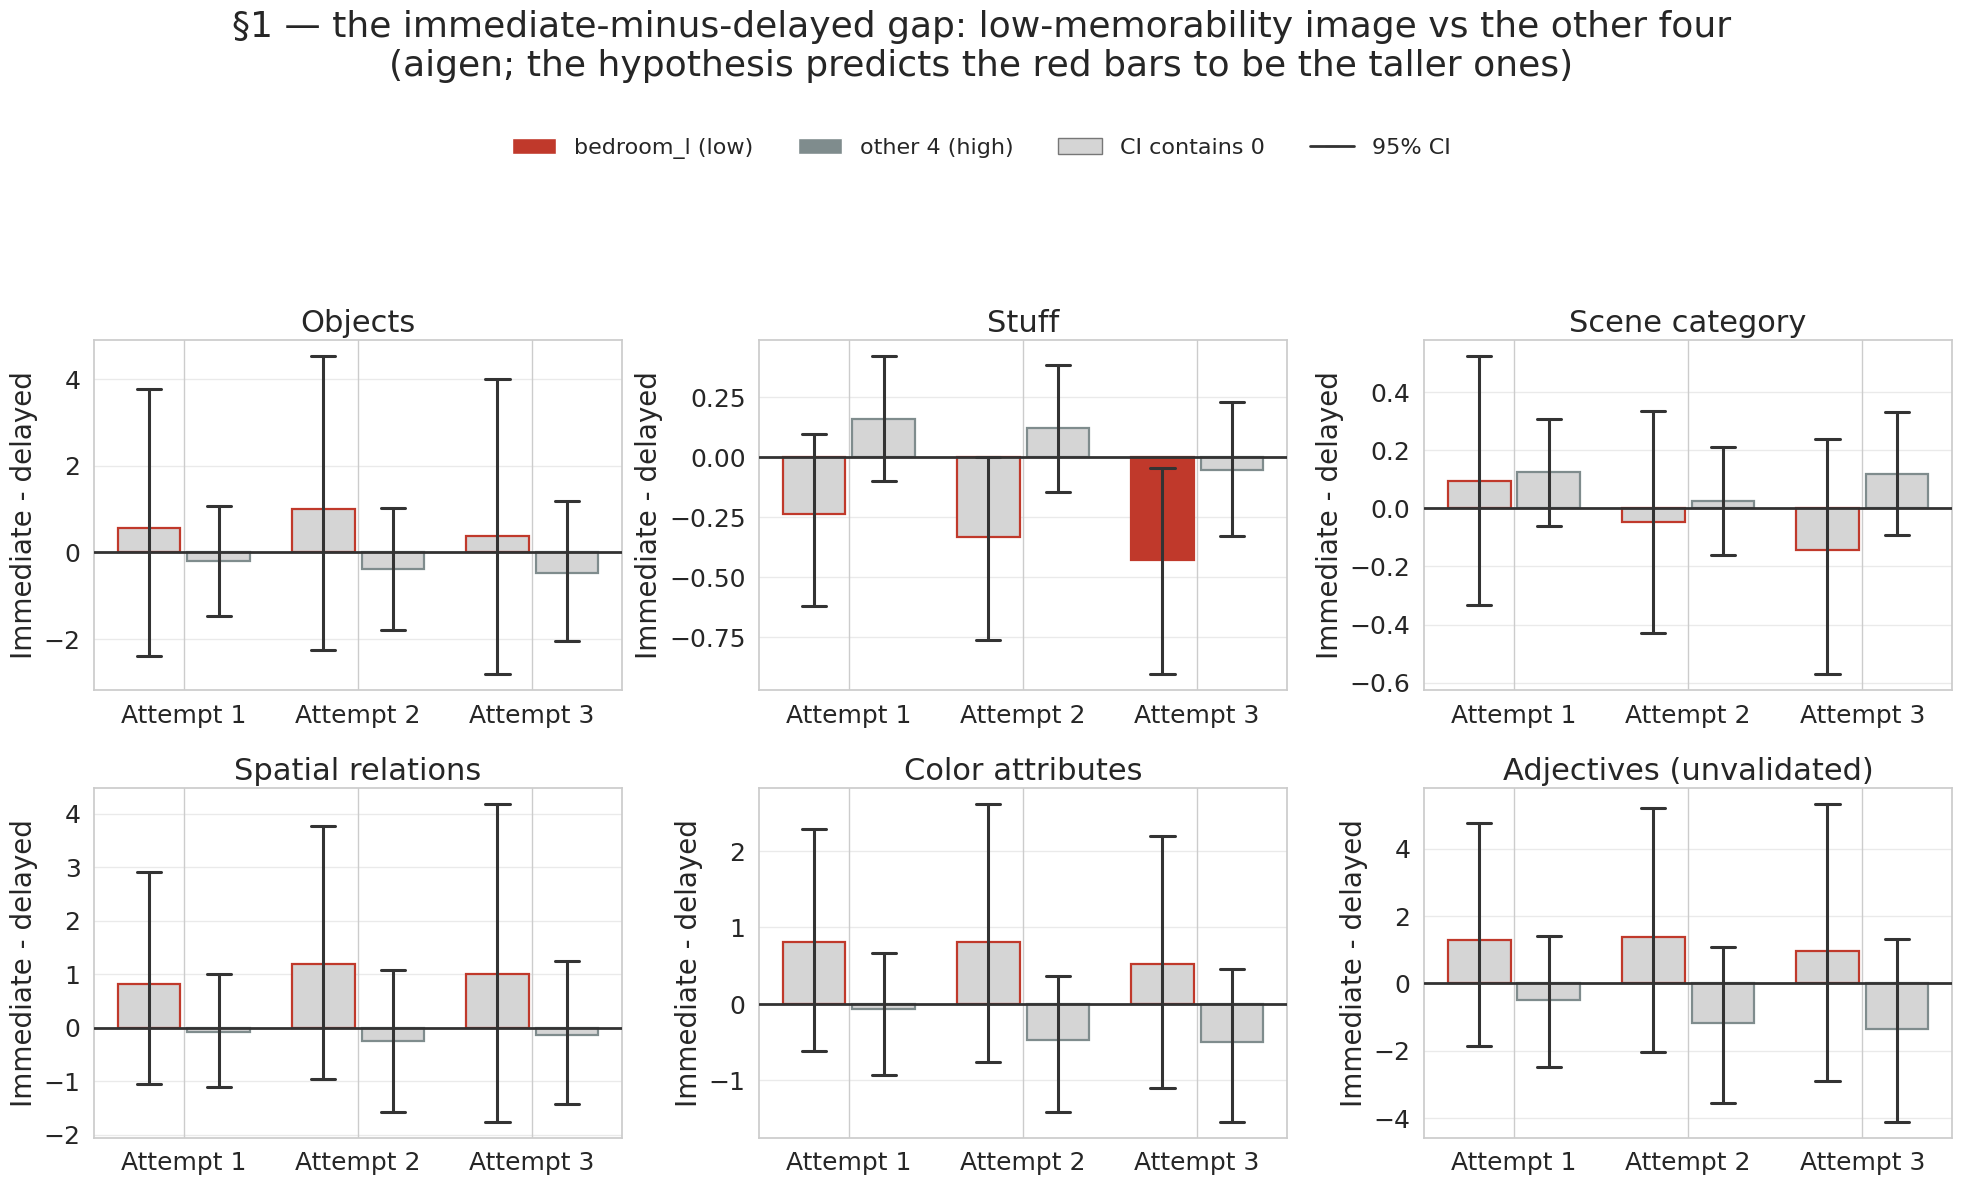

In [11]:
# The gap per category, low vs high images, side by side. Grey = CI contains zero.
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
IMG_SETS = ["bedroom_l (low)", "other 4 (high)"]
IMG_COLORS = {"bedroom_l (low)": "#c0392b", "other 4 (high)": "#7f8c8d"}
for ax, cat in zip(axes.ravel(), CATEGORIES):
    sub = gaps[gaps["category"] == cat]
    offs, width = geom(IMG_SETS)
    for _, r in sub.iterrows():
        i = ATTEMPTS.index(int(r["attempt"]))
        x = i + offs[r["images"]]
        ax.bar(x, r["gap"], width=width * 0.9, zorder=2,
               color=IMG_COLORS[r["images"]] if r["excludes_0"] else "#d5d5d5",
               edgecolor=IMG_COLORS[r["images"]], linewidth=1.6)
        draw_interval(ax, x, r["lo"], r["hi"], width=width * 0.35)
    ax.axhline(0, color="#333333", lw=2, zorder=4)
    ax.set_xticks(range(len(ATTEMPTS)))
    ax.set_xticklabels([f"Attempt {a}" for a in ATTEMPTS])
    ax.set_title(cat_label(cat, COUNT_MODE))
    ax.set_ylabel("Immediate - delayed")
    ax.grid(True, axis="y", alpha=0.4)
handles = [Patch(facecolor=IMG_COLORS[s], label=s) for s in IMG_SETS]
handles += [Patch(facecolor="#d5d5d5", edgecolor="#777777", label="CI contains 0"),
            Line2D([], [], color=CI_COLOR, lw=2, marker="_", markersize=10, label="95% CI")]
fig.suptitle("§1 — the immediate-minus-delayed gap: low-memorability image vs the other four\n"
             "(aigen; the hypothesis predicts the red bars to be the taller ones)", y=0.995)
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.905), ncol=4,
           frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.855))
save_fig(fig, GRAPHS / "s1_bedroom_imm_del_gap.png")
plt.show()

---
# 2. The objects themselves

Two questions, one frame (`OBJ` — every extracted object, tagger artifacts like `corner` and
`background` removed in §0.1):

1. **Attempt 1** — what are the most prominent objects, how many participants share them, and
   are they just the typical contents of the scene?
2. **Attempts 2–3** — which objects get *added*, and do the additions repeat across people?

Counts are **participants who mentioned it at least once**, not mentions: a participant who
writes "chair" three times counts once, and cells with different N stay comparable.

Bars are shaded by the judge's verdict, so an object that many people report and the judge
rejects stays visible instead of being silently dropped.

**aigen first**, as agreed; the helpers take a `gen=` argument so `plain` and `nogen` are one
call away once we have settled the layout.

In [12]:
GEN = "aigen"          # switch to "nogen" / "plain" once the layout is settled
TOP_N = 10


def top_items(gt, task=None, attempts=(1,), col=None, n=TOP_N, gen=GEN, data=None):
    """Most-mentioned objects in one cell: item, how many participants said it, share, and
    the judge's acceptance rate among those participants."""
    col = col or NORM
    d = (OBJ if data is None else data)
    d = d[(d["gt"] == gt) & (d["generation"] == gen)]
    if task:
        d = d[d["task"] == task]
    if attempts:
        d = d[d["attempt"].isin(attempts)]
    N = d["uid"].nunique()
    if not N:
        return pd.DataFrame(columns=["item", "n_ppt", "N", "share", "frac_in_image"]), 0
    seen = d.drop_duplicates(["uid", col])
    out = (seen.groupby(col).agg(n_ppt=("uid", "nunique"),
                                 frac_in_image=("in_image", "mean")).reset_index()
               .rename(columns={col: "item"}))
    out["N"] = N
    out["share"] = out["n_ppt"] / N
    return out.sort_values("n_ppt", ascending=False).head(n).reset_index(drop=True), N


def added_items(gt, task, attempt, col=None, n=TOP_N, gen=GEN, data=None):
    """Objects a participant has at `attempt` but did NOT have at `attempt - 1`, counted by
    how many participants added each. This is the per-participant set difference, so it is
    genuinely 'new to that person', not 'new to the group'."""
    col = col or NORM
    d = (OBJ if data is None else data)
    d = d[(d["gt"] == gt) & (d["generation"] == gen) & (d["task"] == task)]
    sets, verdict = {}, {}
    for (uid, att), g in d.groupby(["uid", "attempt"]):
        sets[(uid, att)] = set(g[col])
        for it, ok in zip(g[col], g["in_image"]):
            verdict.setdefault((att, it), []).append(ok)
    uids = sorted({u for u, a in sets if a == attempt and (u, attempt - 1) in sets})
    cnt = {}
    for u in uids:
        for it in sets[(u, attempt)] - sets[(u, attempt - 1)]:
            cnt[it] = cnt.get(it, 0) + 1
    if not cnt:
        return pd.DataFrame(columns=["item", "n_ppt", "N", "share", "frac_in_image"]), 0
    out = pd.DataFrame({"item": list(cnt), "n_ppt": list(cnt.values())})
    out["N"] = len(uids)
    out["share"] = out["n_ppt"] / len(uids)
    out["frac_in_image"] = [np.mean(verdict.get((attempt, i), [np.nan])) for i in out["item"]]
    return out.sort_values("n_ppt", ascending=False).head(n).reset_index(drop=True), len(uids)


def barh_items(ax, tab, N, color, title, xmax=None):
    """One horizontal top-N panel. Hatched red = the judge rejected it for most of the
    participants who said it. The label is 'n/N' because 'how many repeat it' is the
    question - the percentage is secondary and printed after it."""
    if tab.empty:
        ax.set_visible(False)
        return 0
    t = tab[::-1]
    bars = ax.barh(range(len(t)), t["n_ppt"], color=color, height=0.72, edgecolor="white",
                   zorder=2)
    for b, f in zip(bars, t["frac_in_image"]):
        if not np.isnan(f) and f < 0.5:
            b.set_hatch("xx"); b.set_edgecolor("#c0392b")
    top = xmax or max(t["n_ppt"].max(), 1)
    for i, (v, s) in enumerate(zip(t["n_ppt"], t["share"])):
        ax.text(v + 0.04 * top, i, f"{int(v)}/{N}  ({s:.0%})", va="center", fontsize=13,
                color=BAR_LABEL_COLOR)
    ax.set_yticks(range(len(t)))
    ax.set_yticklabels(t["item"], fontsize=15)
    ax.set_xlim(0, top * 1.45)
    ax.set_xlabel(f"Participants (of {N})")
    ax.set_title(title)
    ax.grid(True, axis="x", alpha=0.35)
    return top

### 2.1 The 10 most common objects at attempt 1

One figure per GT image, one column per task. Ordering is per panel — each column is that
condition's own top 10, so the same row position is *not* the same object across columns; the
object names are the data here, not the bar heights.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_bedroom_l_item_norm.png


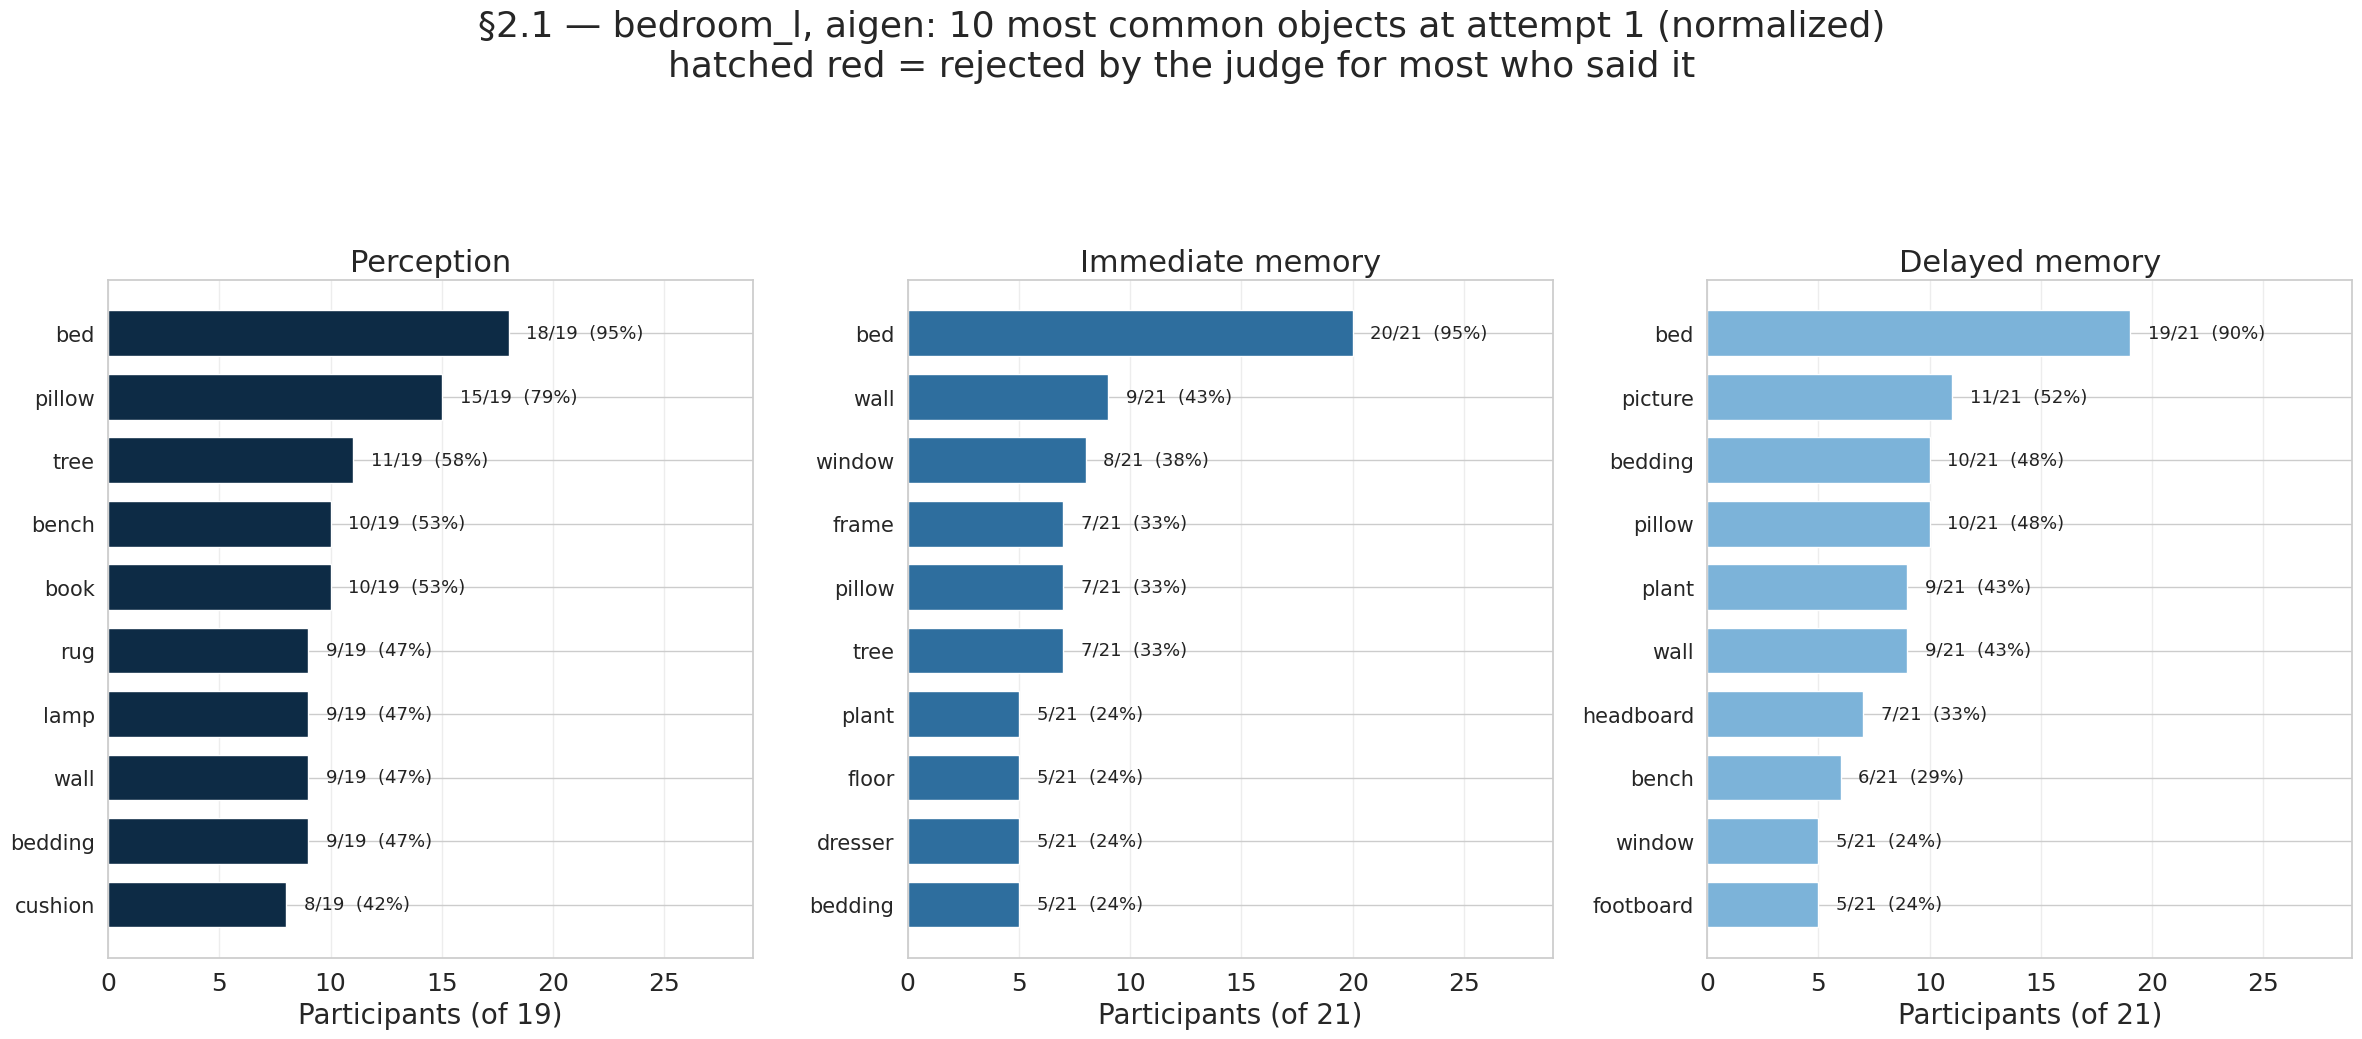

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_living_room_h_item_norm.png


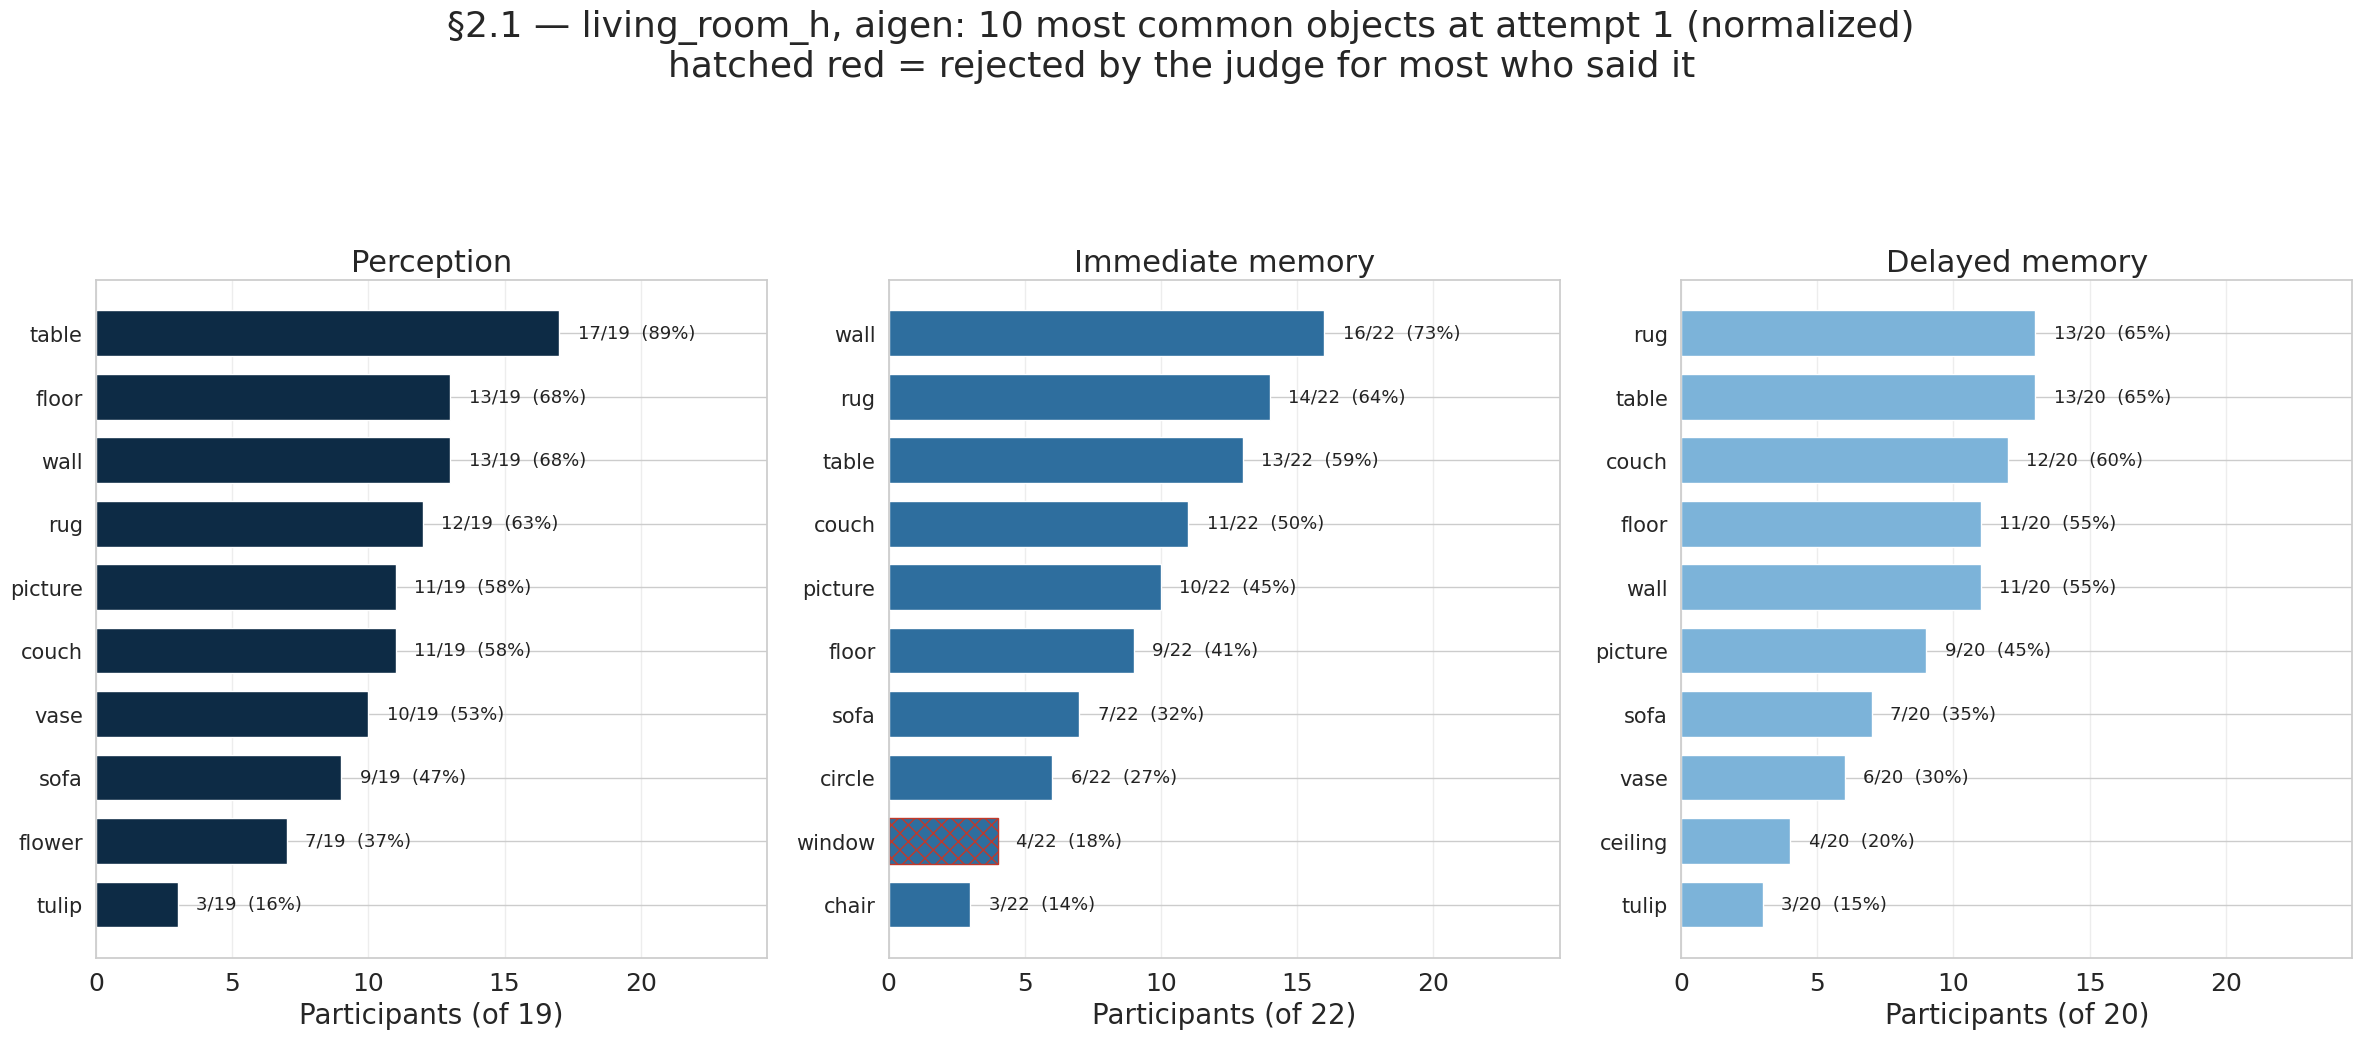

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_conference_room_h_item_norm.png


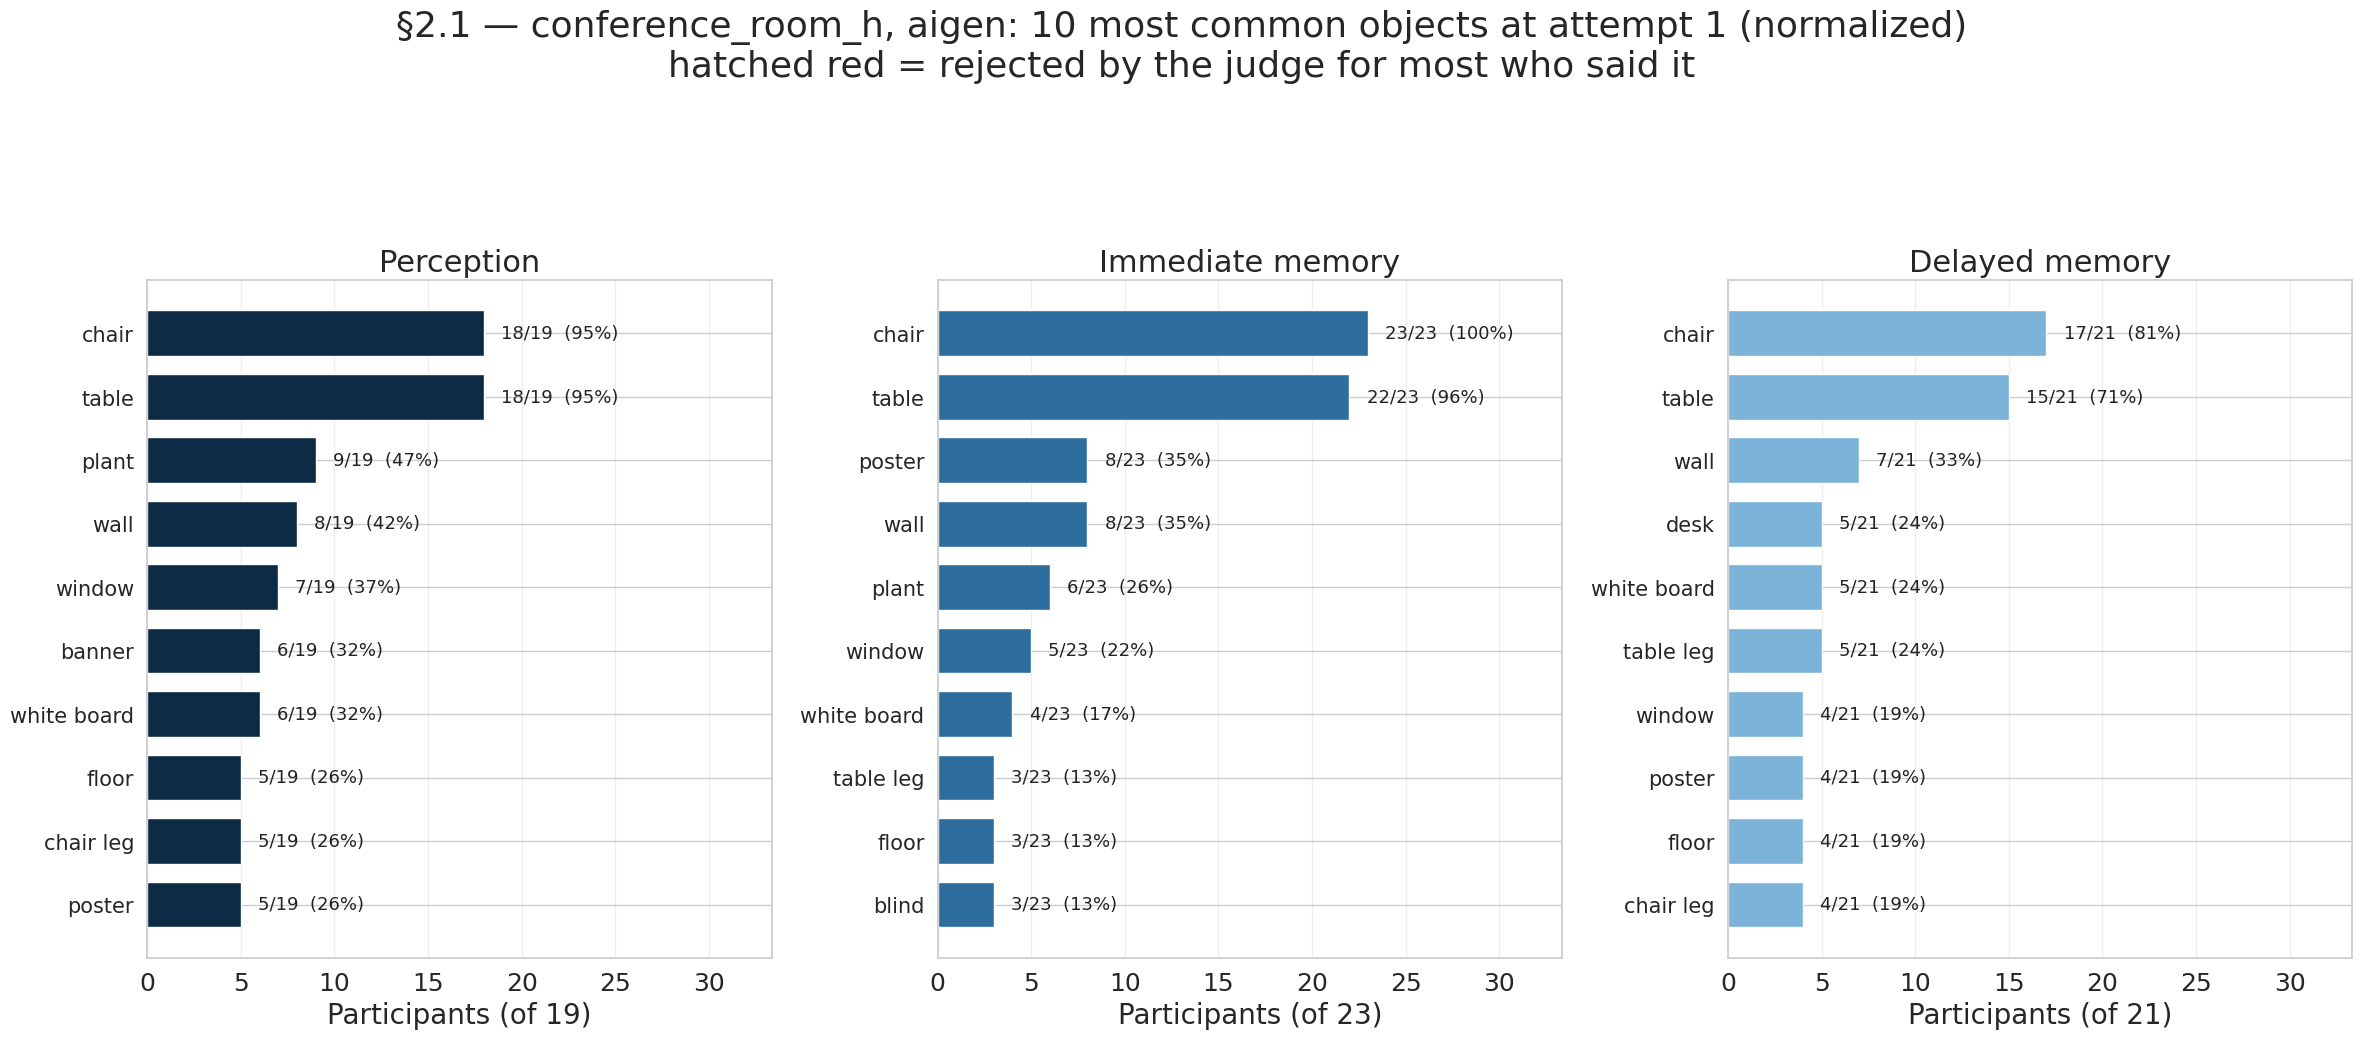

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_lighthouse_h_item_norm.png


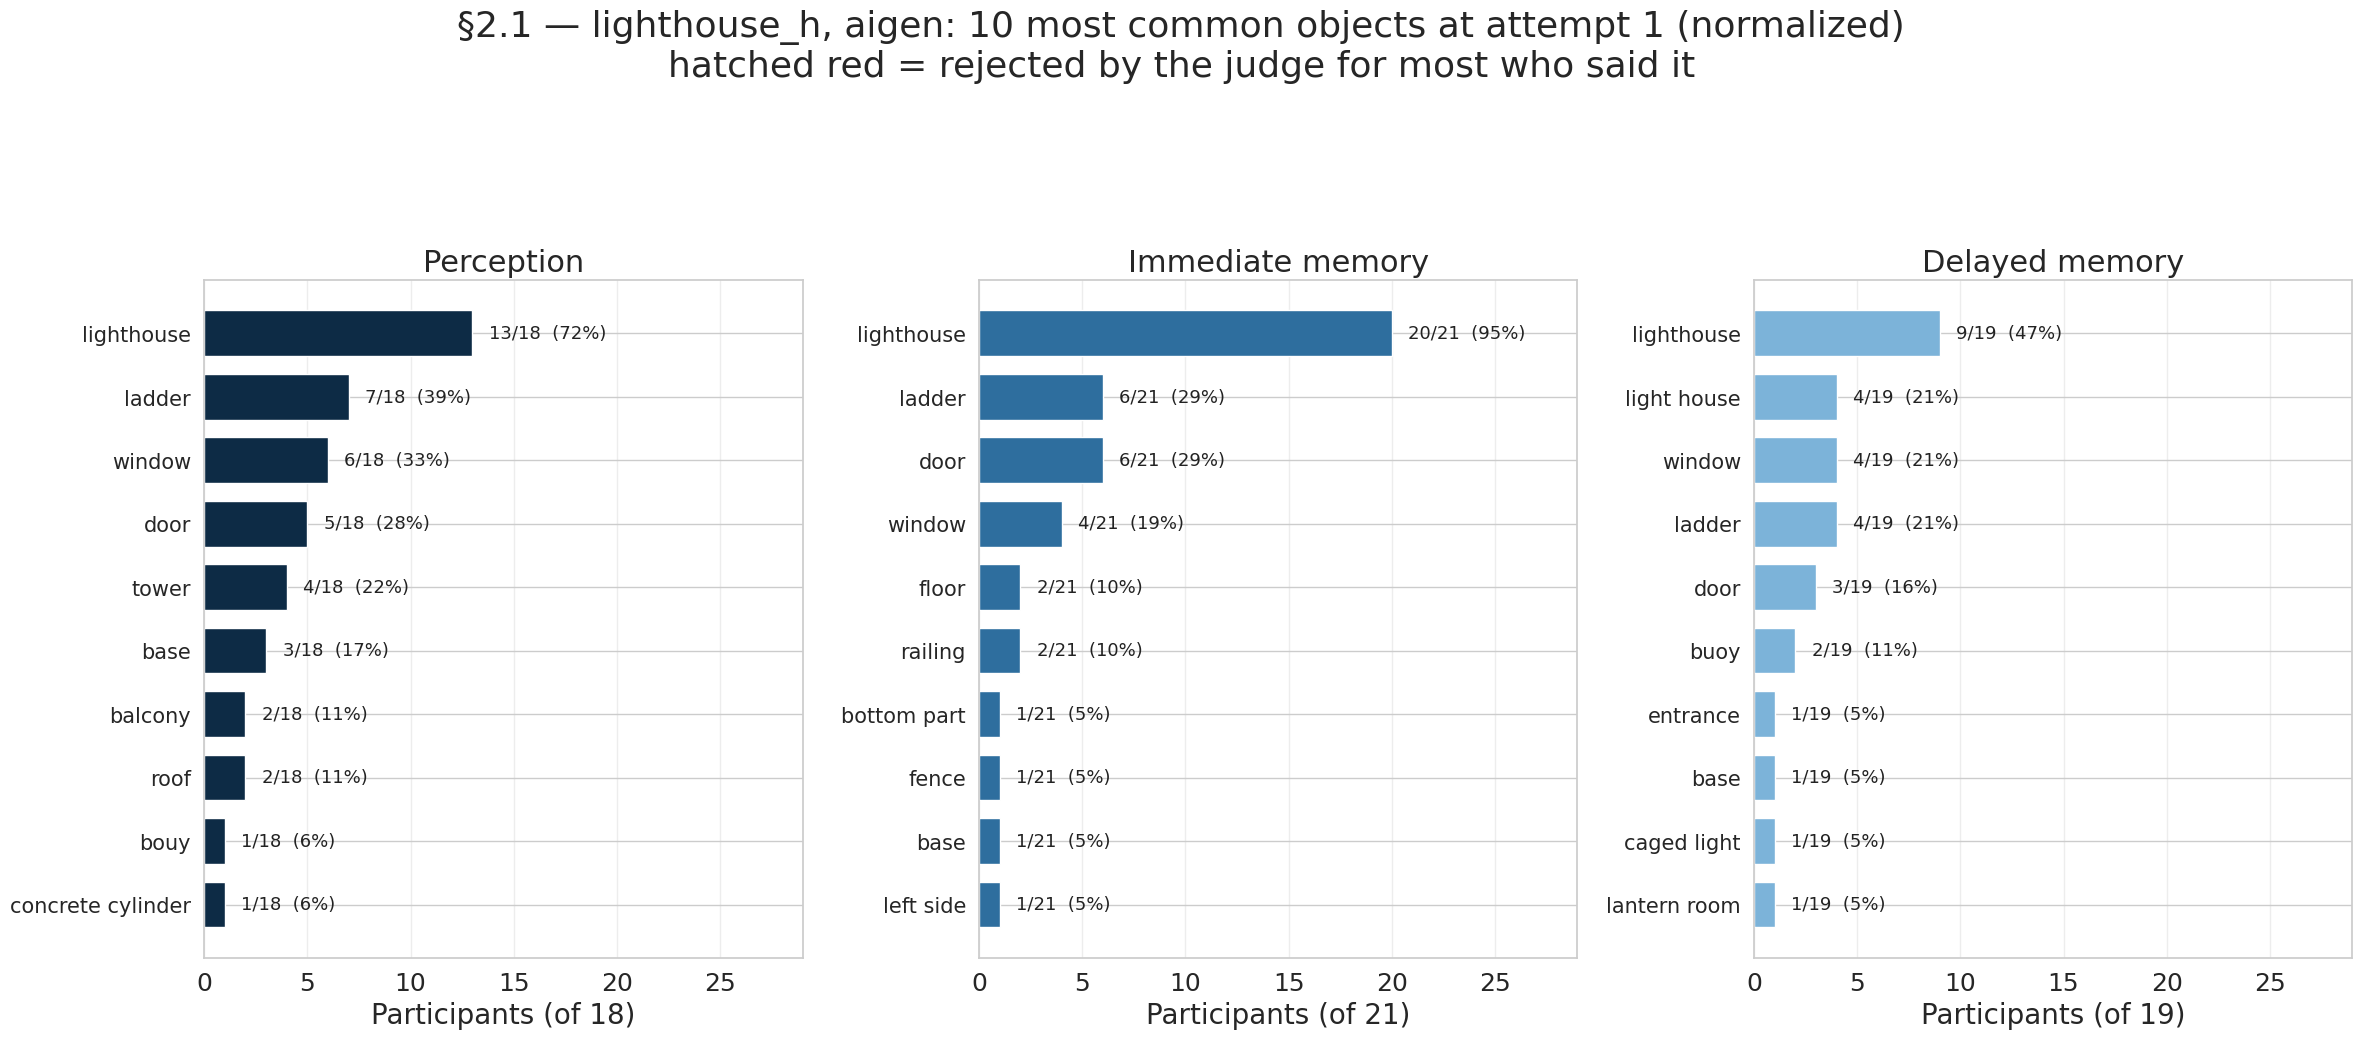

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_playground_h_item_norm.png


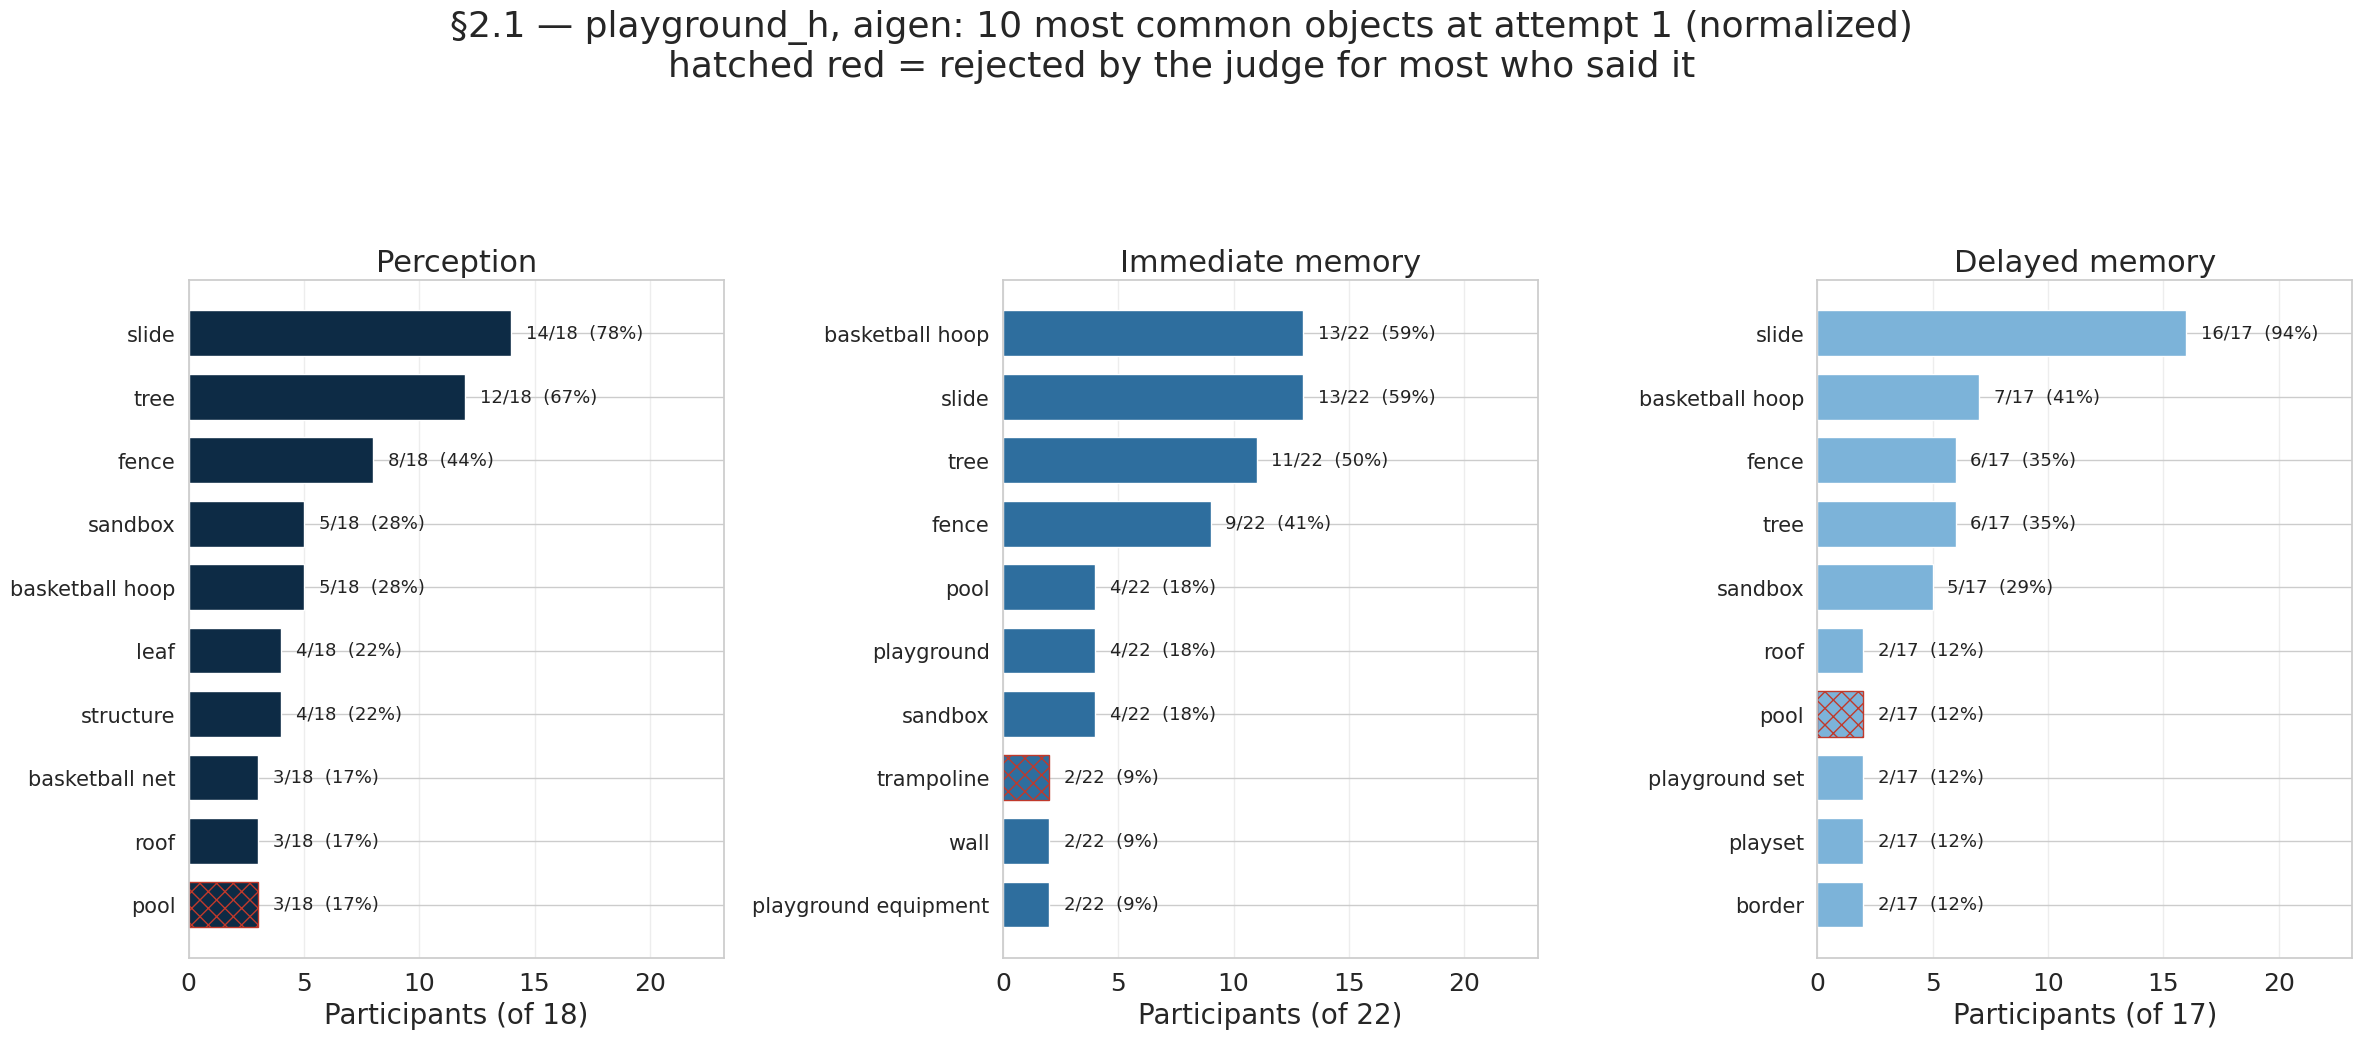

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_bedroom_l_item.png


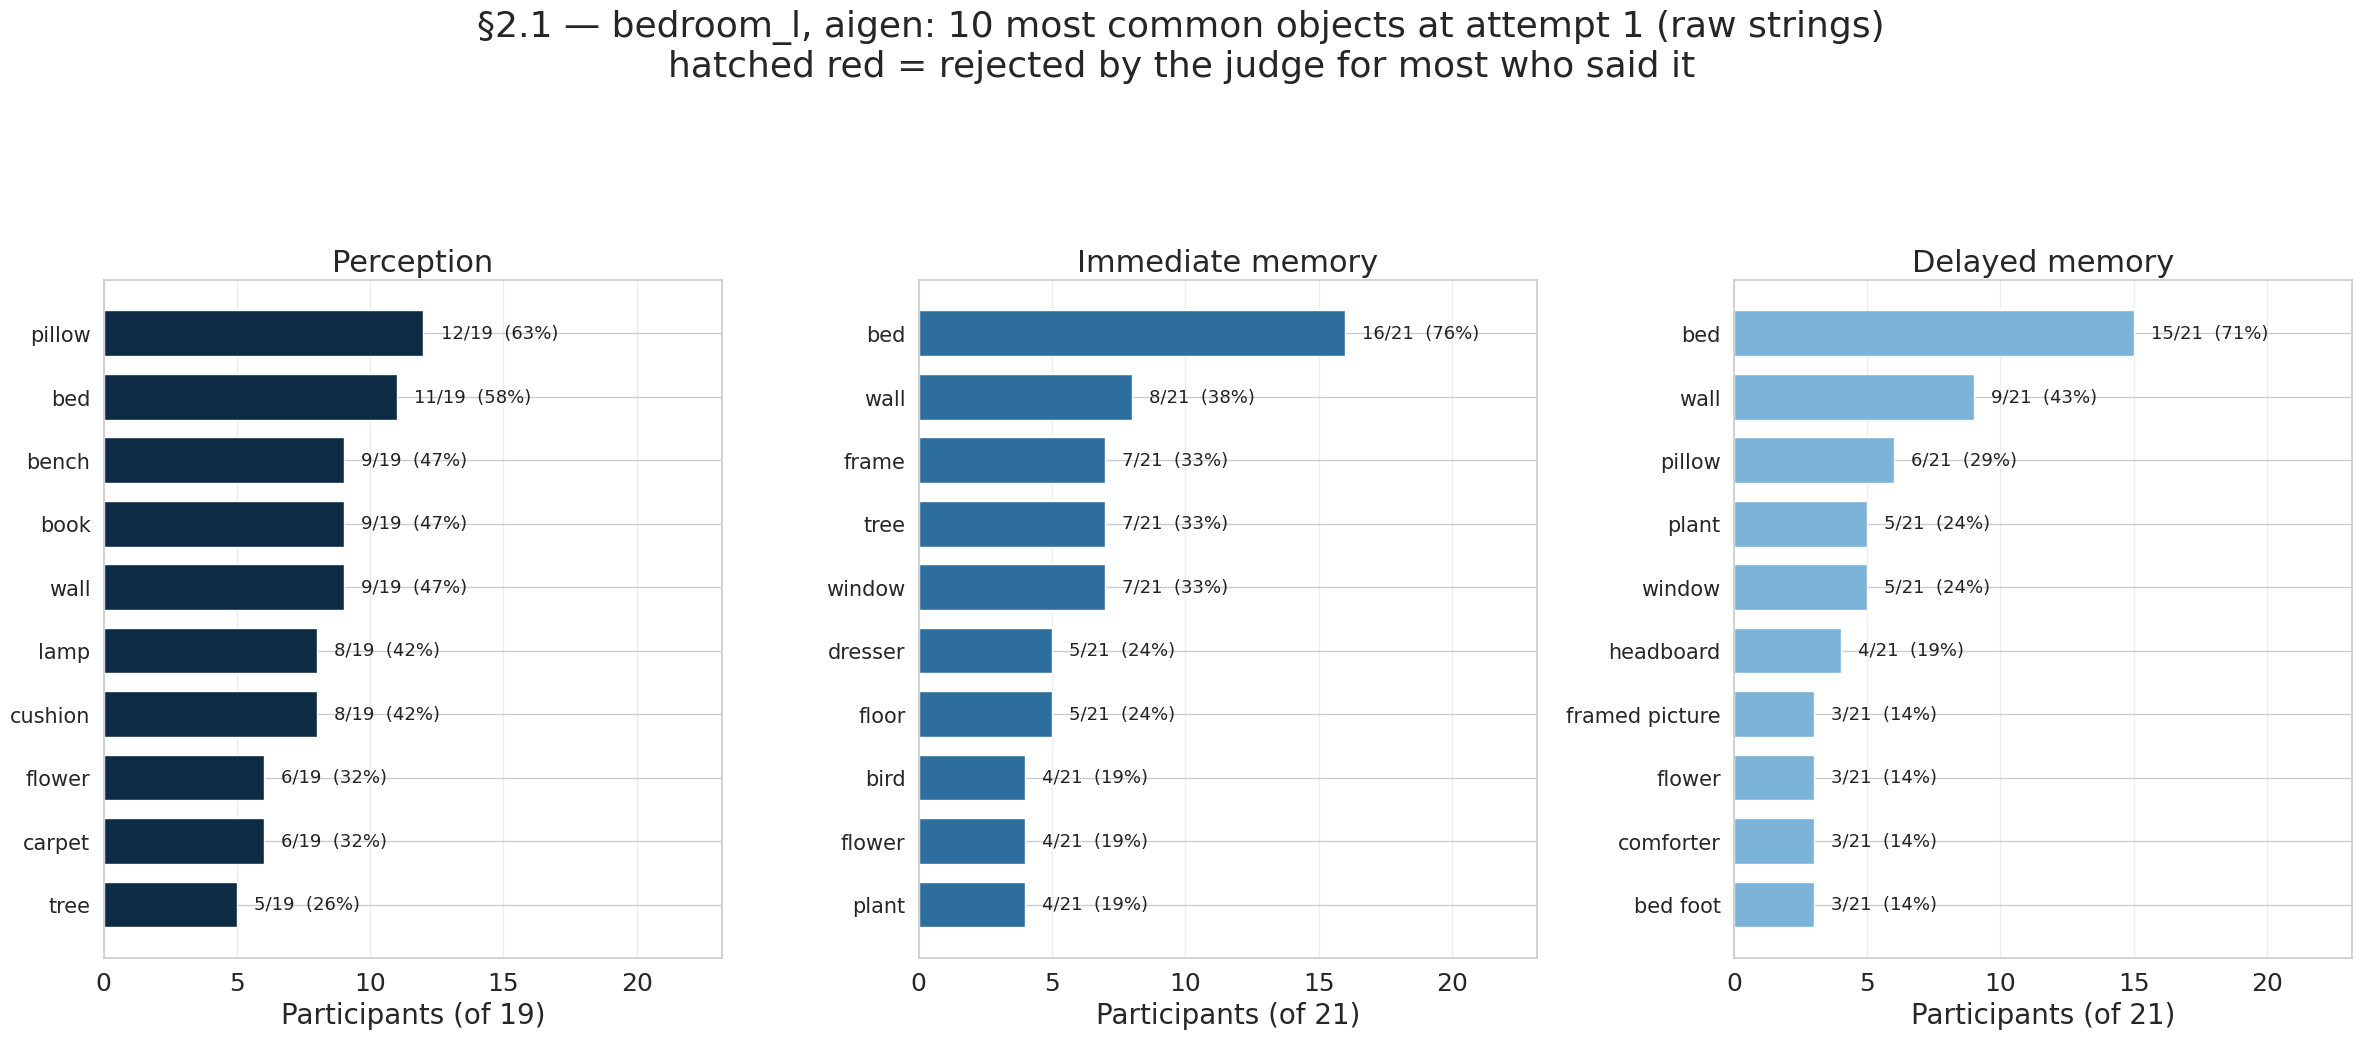

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_living_room_h_item.png


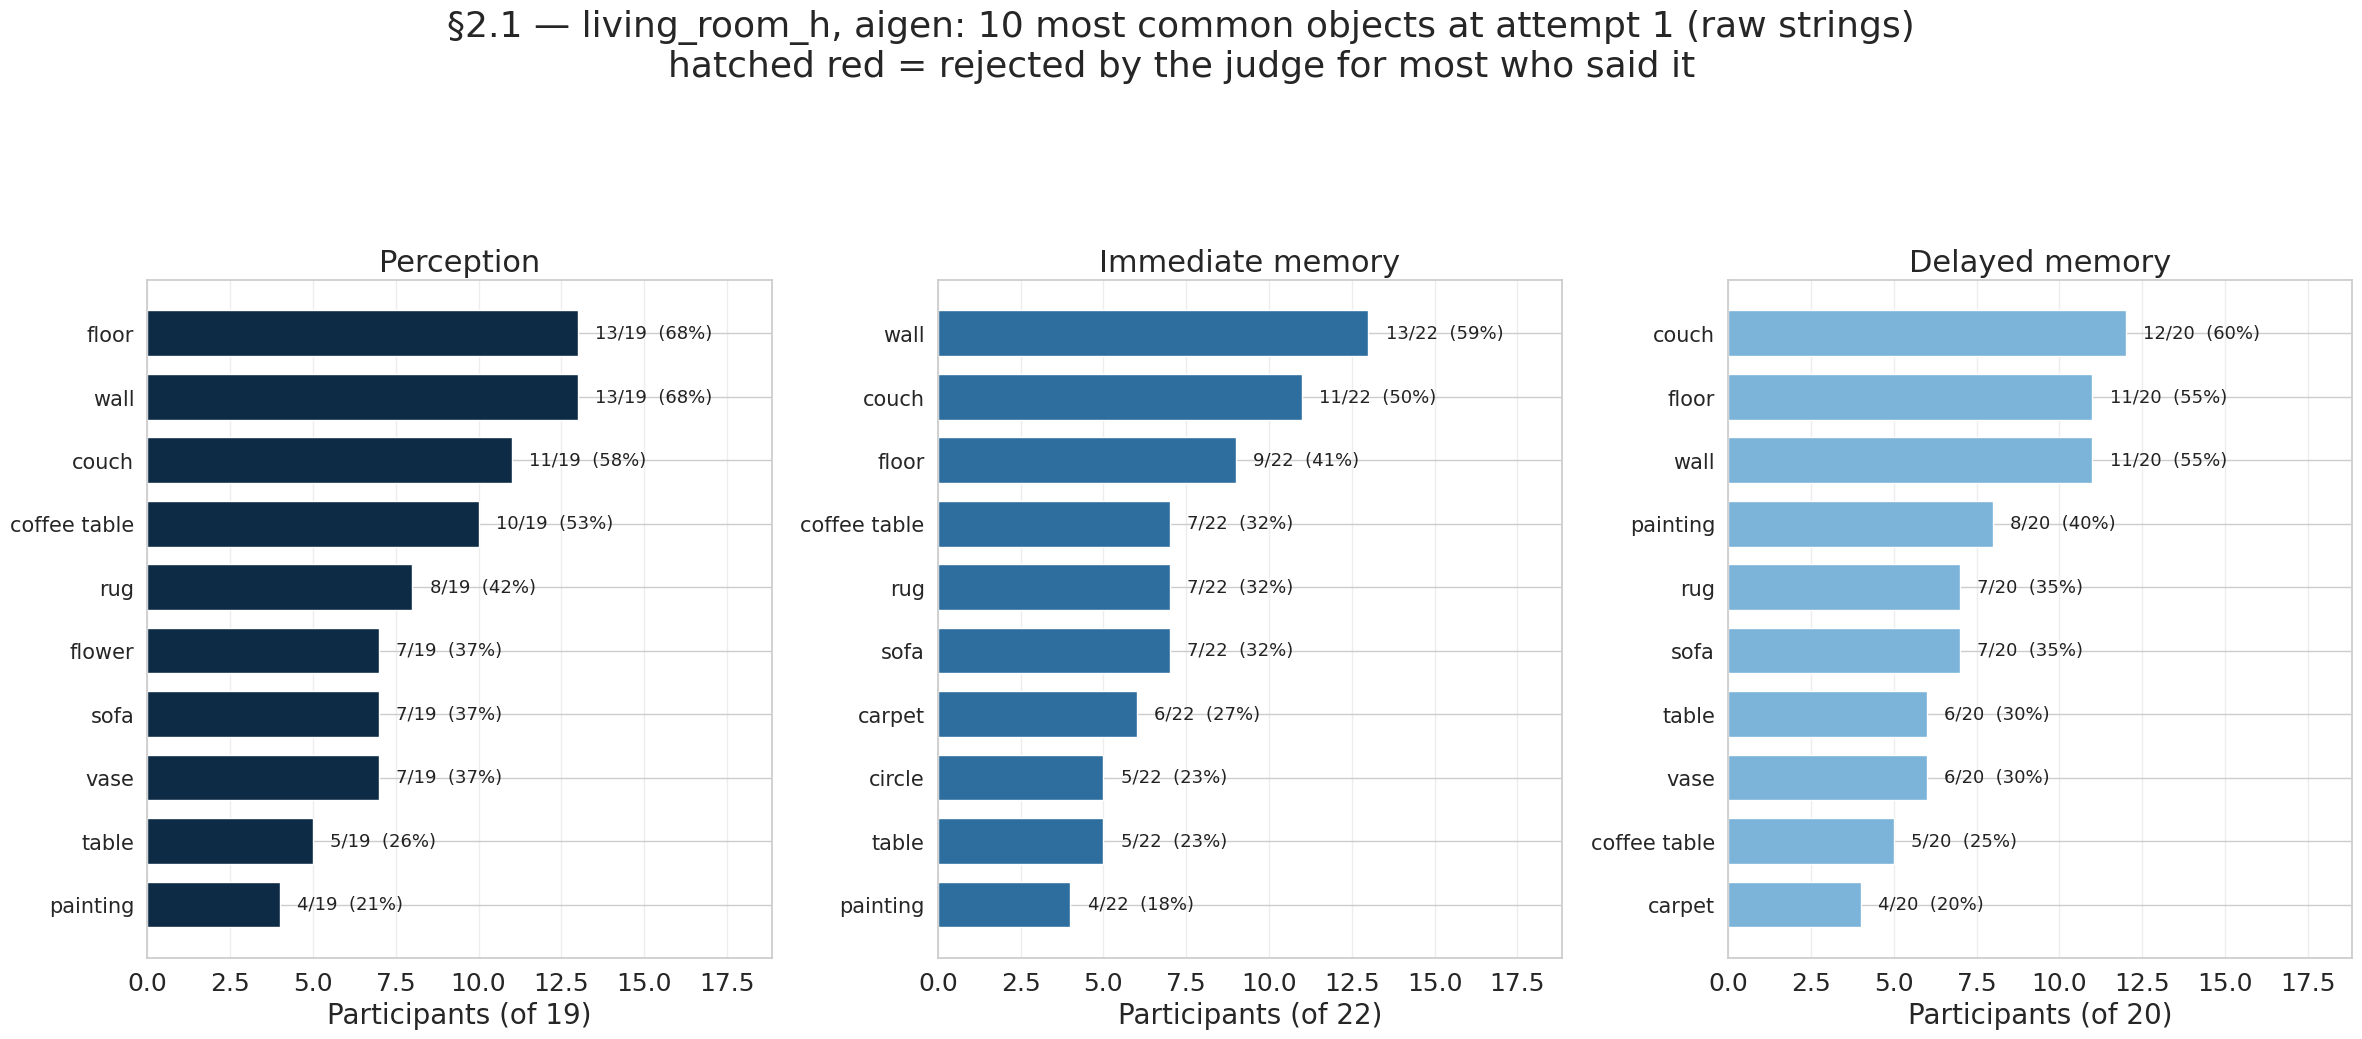

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_conference_room_h_item.png


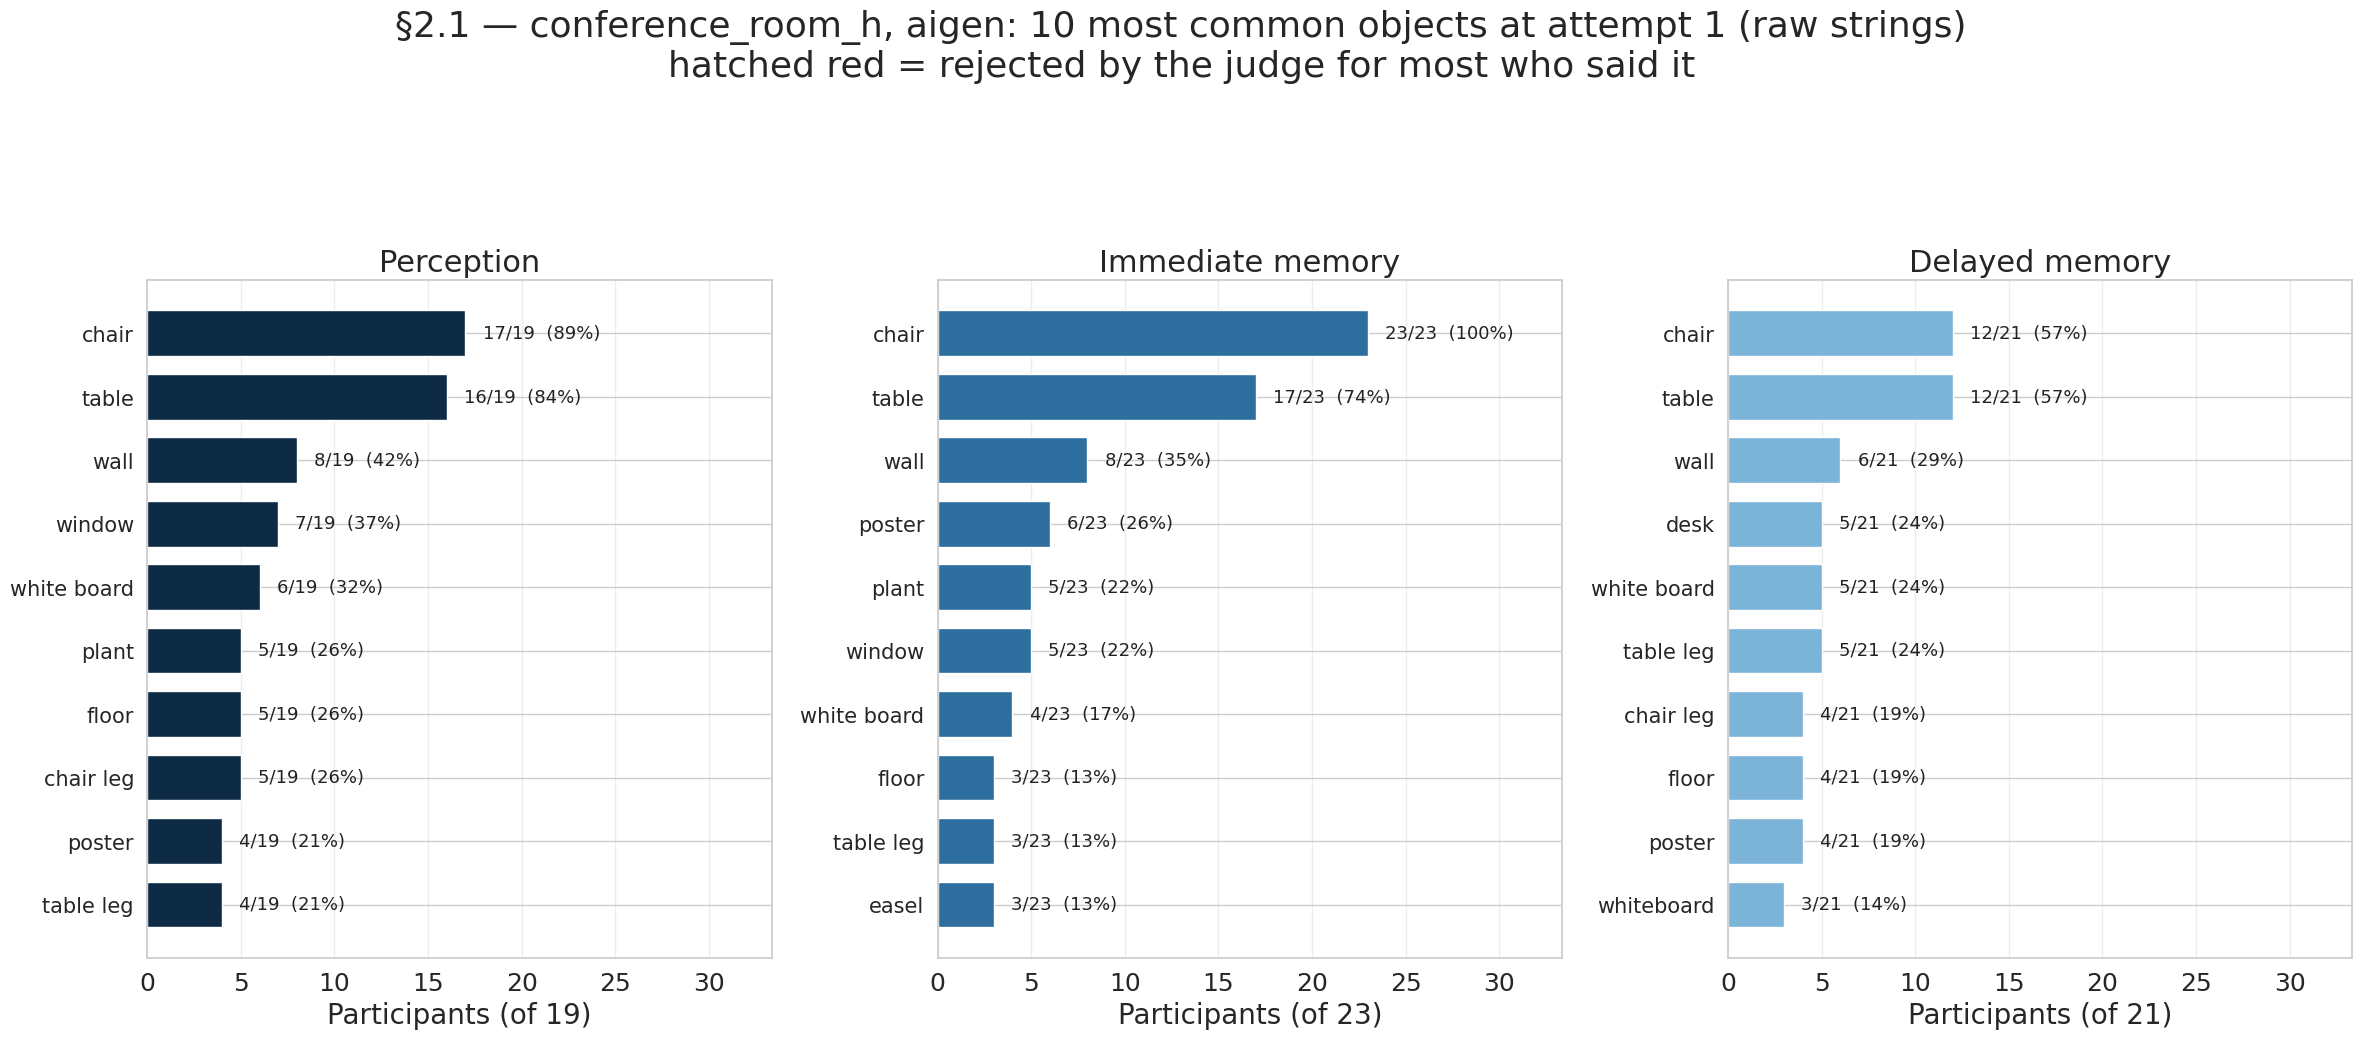

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_lighthouse_h_item.png


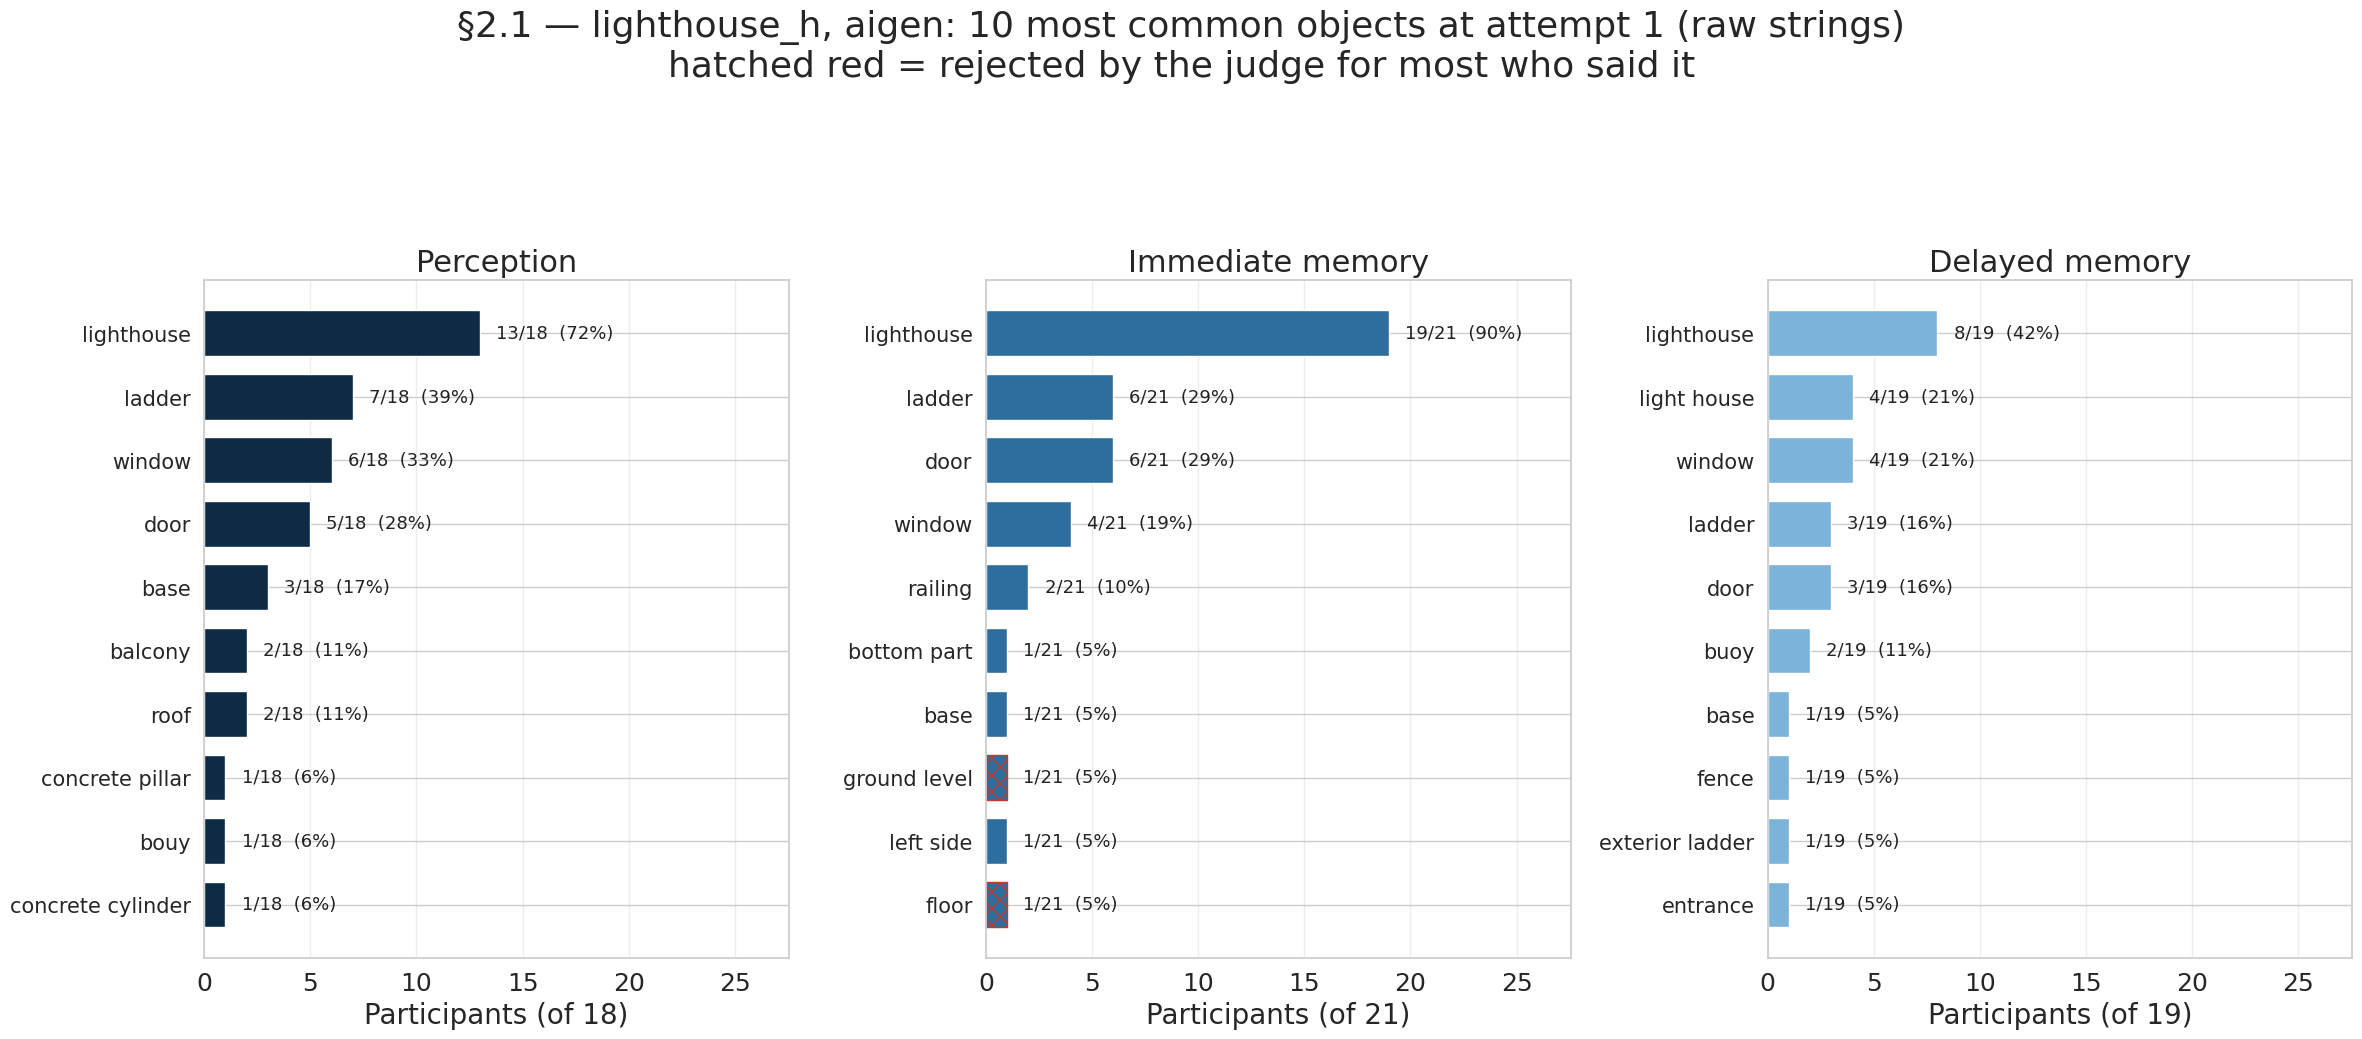

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/s2_top10_attempt1_aigen_playground_h_item.png


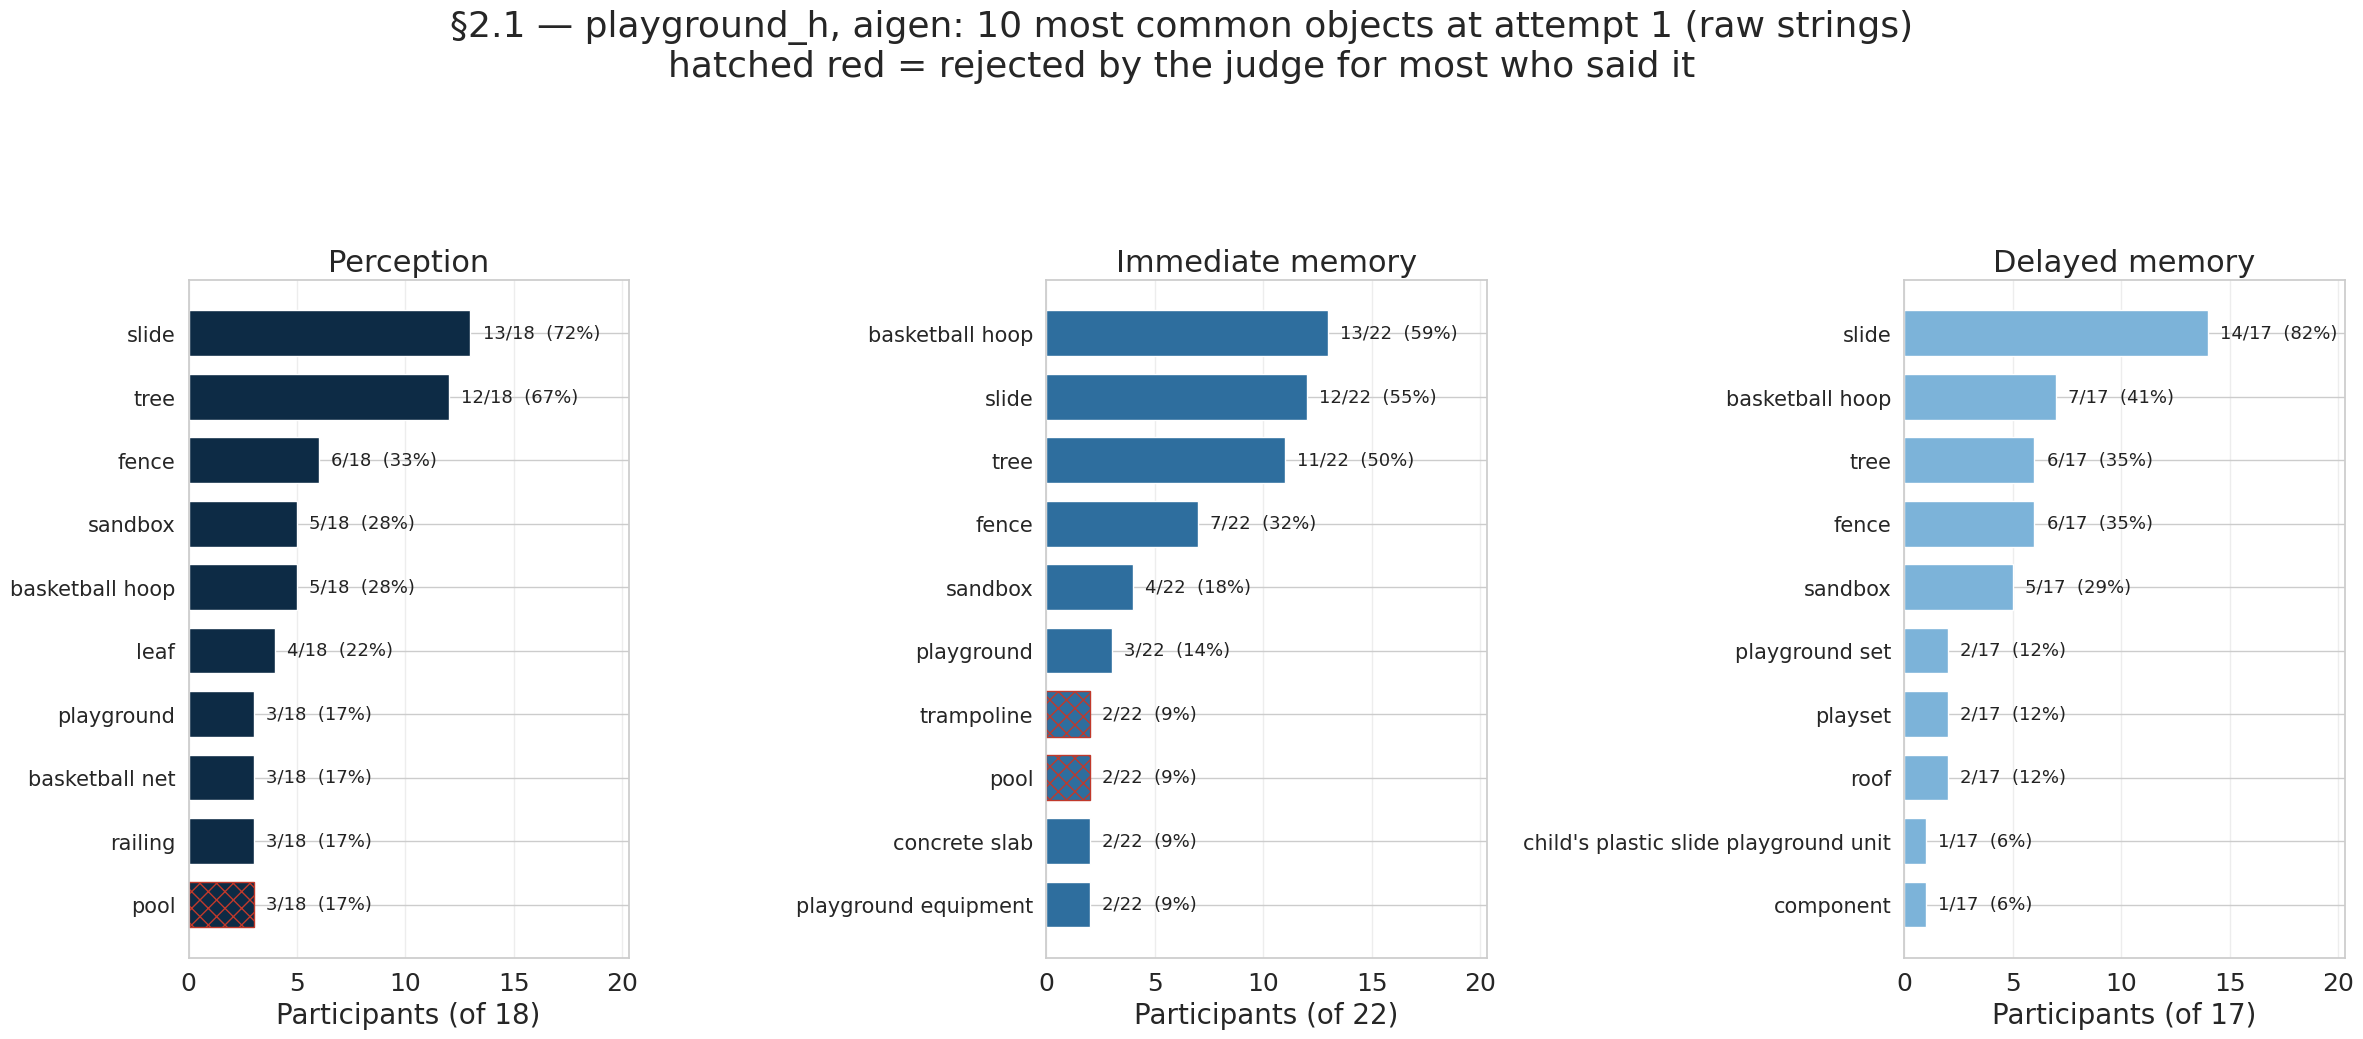

In [13]:
def plot_top_attempt1(gt, col=None, gen=GEN, save=True):
    col = col or NORM
    fig, axes = plt.subplots(1, 3, figsize=(24, 0.62 * TOP_N + 4.5))
    xmax = 0
    tabs = {}
    for task in TASK_ORDER:
        tabs[task], N = top_items(gt, task, attempts=(1,), col=col, gen=gen)
        xmax = max(xmax, tabs[task]["n_ppt"].max() if not tabs[task].empty else 0)
    for ax, task in enumerate_tasks(axes):
        tab = tabs[task]
        N = int(tab["N"].iloc[0]) if not tab.empty else 0
        barh_items(ax, tab, N, TASK_COLORS[task], TASK_LABELS[task], xmax=xmax)
    fig.suptitle(f"§2.1 — {GT_LABELS[gt]}, {gen}: 10 most common objects at attempt 1 "
                 f"({NORM_LABEL[col]})\nhatched red = rejected by the judge for most who said it")
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    if save:
        save_fig(fig, GRAPHS / f"s2_top10_attempt1_{gen}_{GT_LABELS[gt]}_{col}.png")
    plt.show()


for COL in NORM_MODES:
    for gt in GT_ORDER:
        plot_top_attempt1(gt, col=COL)

### 2.2 The 10 most commonly *added* objects at attempts 2 and 3

Per participant, the objects present at attempt *n* and absent at attempt *n−1*. Rows are the
two transitions, columns the three tasks.

**Watch the x axis, not the ranking.** If the top added object is shared by 3 or 4 of ~21
participants and the rest sit at 1, the additions are essentially idiosyncratic — which is a
result, and §2.5 quantifies it.

In [ ]:
def plot_added(gt, col=None, gen=GEN, save=True):
    col = col or NORM
    fig, axes = plt.subplots(2, 3, figsize=(24, 1.1 * TOP_N + 6))
    tabs, xmax = {}, 0
    for att in (2, 3):
        for task in TASK_ORDER:
            tabs[(att, task)], _ = added_items(gt, task, att, col=col, gen=gen)
            if not tabs[(att, task)].empty:
                xmax = max(xmax, tabs[(att, task)]["n_ppt"].max())
    for r, att in enumerate((2, 3)):
        for c, task in enumerate(TASK_ORDER):
            ax = axes[r, c]
            tab = tabs[(att, task)]
            N = int(tab["N"].iloc[0]) if not tab.empty else 0
            barh_items(ax, tab, N, TASK_COLORS[task],
                       f"{TASK_LABELS[task]} — added at attempt {att}", xmax=xmax)
    fig.suptitle(f"§2.2 — {GT_LABELS[gt]}, {gen}: most commonly ADDED objects ({NORM_LABEL[col]})\n"
                 "per participant, objects present at this attempt and absent at the previous one")
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    if save:
        save_fig(fig, GRAPHS / f"s2_top10_added_{gen}_{GT_LABELS[gt]}_{col}.png")
    plt.show()


for COL in NORM_MODES:
    for gt in GT_ORDER:
        plot_added(gt, col=COL)

### 2.3 First-attempt objects vs later additions

The view from the previous notebook (its 5.2), pooled over the three tasks: the attempt-1
vocabulary beside the attempt-2/3 additions for the same image. Overlap between the two lists
means typical items simply arriving late; disjoint lists with much lower shares on the right
mean individual elaboration.

In [ ]:
def plot_first_vs_added(gt, col=None, gen=GEN, save=True):
    col = col or NORM
    first, N1 = top_items(gt, task=None, attempts=(1,), col=col, gen=gen)
    added = pd.concat([added_items(gt, t, a, col=col, gen=gen)[0]
                       for t in TASK_ORDER for a in (2, 3)], ignore_index=True)
    if not added.empty:
        added = (added.groupby("item", as_index=False)
                      .agg(n_ppt=("n_ppt", "sum"), frac_in_image=("frac_in_image", "mean"))
                      .sort_values("n_ppt", ascending=False).head(TOP_N))
        Na = OBJ[(OBJ["gt"] == gt) & (OBJ["generation"] == gen)
                 & (OBJ["attempt"] > 1)]["uid"].nunique()
        added["N"], added["share"] = Na, added["n_ppt"] / Na

    fig, axes = plt.subplots(1, 2, figsize=(20, 0.62 * TOP_N + 4.5))
    barh_items(axes[0], first, N1, "#2c7fb8", "Attempt 1 — most reported")
    barh_items(axes[1], added, int(added["N"].iloc[0]) if not added.empty else 0, "#d95f02",
               "Attempts 2–3 — most added")
    overlap = set(first["item"]) & set(added["item"] if not added.empty else [])
    fig.suptitle(f"§2.3 — {GT_LABELS[gt]}, {gen}: first-attempt objects vs later additions "
                 f"({NORM_LABEL[col]})\n{len(overlap)}/{TOP_N} items in both lists"
                 + (f": {', '.join(sorted(overlap))}" if overlap else ""))
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    if save:
        save_fig(fig, GRAPHS / f"s2_first_vs_added_{gen}_{GT_LABELS[gt]}_{col}.png")
    plt.show()


for COL in NORM_MODES:
    for gt in GT_ORDER:
        plot_first_vs_added(gt, col=COL)

### 2.4 The actual data — participant × object

The plot for *looking at the data* rather than summarising it. Rows are participants (sorted
by how many objects they reported), columns are the image's most common objects (sorted by
prevalence), and a filled cell means that participant named that object at attempt 1.

Three things are readable at a glance that no bar chart shows: the **core vocabulary** (solid
left-hand columns), the **idiosyncratic tail** (sparse right-hand columns), and the **verbose
participants** (dense top rows) who drive the group means everywhere else in this notebook.

In [ ]:
def plot_ppt_matrix(gt, task, n_obj=25, col=None, gen=GEN, ax=None, save=True):
    col = col or NORM
    d = OBJ[(OBJ["gt"] == gt) & (OBJ["generation"] == gen) & (OBJ["task"] == task)
            & (OBJ["attempt"] == 1)]
    if d.empty:
        return
    order = (d.drop_duplicates(["uid", col]).groupby(col)["uid"].nunique()
              .sort_values(ascending=False).head(n_obj).index.tolist())
    m = (d[d[col].isin(order)].assign(v=1)
         .pivot_table(index="uid", columns=col, values="v", aggfunc="max", fill_value=0)
         .reindex(columns=order, fill_value=0))
    m = m.loc[m.sum(axis=1).sort_values(ascending=False).index]

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(0.55 * len(order) + 6, 0.42 * len(m) + 4))
    ax.imshow(m.values, aspect="auto", cmap=ListedColormap(["#f2f2f2", TASK_COLORS[task]]),
              vmin=0, vmax=1)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=55, ha="right", fontsize=13)
    ax.set_yticks(range(len(m)))
    ax.set_yticklabels([f"{u[:6]}… ({int(n)})" for u, n in zip(m.index, m.sum(axis=1))],
                       fontsize=11)
    ax.set_xticks(np.arange(-.5, len(order), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(m), 1), minor=True)
    ax.grid(which="minor", color="white", lw=1.5)
    ax.tick_params(which="minor", length=0)
    ax.grid(which="major", visible=False)
    ax.set_title(f"{TASK_LABELS[task]} (n={len(m)})")
    if own:
        fig.suptitle(f"§2.4 — {GT_LABELS[gt]}, {gen}, {task}: who said what at attempt 1")
        fig.tight_layout()
        if save:
            save_fig(fig, GRAPHS / f"s2_matrix_{gen}_{GT_LABELS[gt]}_{task}.png")
        plt.show()


for COL in NORM_MODES:
    for gt in GT_ORDER:
        fig, axes = plt.subplots(1, 3, figsize=(34, 11))
        for ax, task in enumerate_tasks(axes):
            plot_ppt_matrix(gt, task, col=COL, ax=ax)
        fig.suptitle(f"§2.4 — {GT_LABELS[gt]}, {GEN}: participant x object at attempt 1 "
                     f"({NORM_LABEL[COL]})\nrows = participants (label shows their object "
                     "count), columns = the 25 most common objects")
        fig.tight_layout(rect=(0, 0, 1, 0.90))
        save_fig(fig, GRAPHS / f"s2_matrix_{GEN}_{GT_LABELS[gt]}_{COL}.png")
        plt.show()

### 2.5 How much do objects repeat at all?

x = "mentioned by exactly *k* participants", y = how many distinct objects sit at that *k*.
A spike at k=1 that dwarfs everything else means most of the reported vocabulary is unique to
one person.

Drawn twice — **raw strings and normalized** — because the height of the k=1 spike is exactly
the quantity that wording inflates. The gap between the two lines is the cost of free-form
tagging, measured.

In [ ]:
def repetition_profile(gt, task, attempts, col, gen=GEN):
    d = OBJ[(OBJ["gt"] == gt) & (OBJ["generation"] == gen) & (OBJ["task"] == task)
            & (OBJ["attempt"].isin(attempts))]
    if d.empty:
        return pd.Series(dtype=int), 0
    k = d.drop_duplicates(["uid", col]).groupby(col)["uid"].nunique()
    return k.value_counts().sort_index(), d["uid"].nunique()


fig, axes = plt.subplots(1, 5, figsize=(30, 6.5), sharey=True)
for ax, gt in zip(axes, GT_ORDER):
    for col, ls, marker in [("item", "--", "s"), ("item_norm", "-", "o")]:
        for task in TASK_ORDER:
            prof, N = repetition_profile(gt, task, (1,), col)
            if prof.empty:
                continue
            ax.plot(prof.index, prof.values, ls=ls, marker=marker, markersize=6,
                    color=TASK_COLORS[task], lw=2.4, alpha=0.9)
    ax.set_yscale("log")
    ax.set_xlabel("Mentioned by k participants")
    ax.set_ylabel("Distinct objects (log)" if ax is axes[0] else "")
    ax.set_title(GT_LABELS[gt])
    ax.grid(True, alpha=0.35)
handles = [Line2D([], [], color=TASK_COLORS[t], lw=2.4, label=TASK_LABELS[t])
           for t in TASK_ORDER]
handles += [Line2D([], [], color="#555555", ls="--", marker="s", lw=2.4, label="raw strings"),
            Line2D([], [], color="#555555", ls="-", marker="o", lw=2.4, label="normalized")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=5,
           frameon=False)
fig.suptitle(f"§2.5 — how many objects are shared by how many people ({GEN}, attempt 1)")
fig.tight_layout(rect=(0, 0, 1, 0.85))
save_fig(fig, GRAPHS / f"s2_repetition_profile_{GEN}.png")
plt.show()

In [ ]:
# The same information as three numbers per cell, which is easier to quote than a curve.
rows = []
for gt in GT_ORDER:
    for task in TASK_ORDER:
        for col in ("item", "item_norm"):
            prof, N = repetition_profile(gt, task, (1,), col)
            if prof.empty:
                continue
            tot = prof.sum()
            rows.append({"gt": GT_LABELS[gt], "task": task, "strings": NORM_LABEL[col],
                         "distinct objects": int(tot),
                         "% said by 1 person only": 100 * prof.get(1, 0) / tot,
                         "% said by >=half": 100 * prof[prof.index >= N / 2].sum() / tot})
rep = pd.DataFrame(rows)
print("Attempt 1 — how concentrated is the vocabulary?")
display(rep.pivot_table(index=["gt", "task"], columns="strings",
                        values=["% said by 1 person only", "% said by >=half"]).round(1))

### 2.6 Core, shared, or unique — per participant

Each participant's attempt-1 objects split three ways: **core** (also named by at least half
the group), **shared** (2 or more people, but under half), **unique** (nobody else said it).

This is "are they mostly agreed or disagreed upon" answered at the level of the individual
rather than the object — and it separates a participant who writes a lot of common things from
one who writes a lot of unusual things.

In [ ]:
def core_shared_unique(gt, task, col=None, gen=GEN):
    col = col or NORM
    d = OBJ[(OBJ["gt"] == gt) & (OBJ["generation"] == gen) & (OBJ["task"] == task)
            & (OBJ["attempt"] == 1)].drop_duplicates(["uid", col])
    if d.empty:
        return pd.DataFrame()
    N = d["uid"].nunique()
    k = d.groupby(col)["uid"].nunique()
    band = np.where(k >= N / 2, "core", np.where(k >= 2, "shared", "unique"))
    kb = dict(zip(k.index, band))
    d = d.assign(band=d[col].map(kb))
    out = (d.pivot_table(index="uid", columns="band", values=col, aggfunc="count",
                         fill_value=0)
             .reindex(columns=["core", "shared", "unique"], fill_value=0))
    return out.loc[out.sum(axis=1).sort_values(ascending=False).index]


BAND_COLORS = {"core": "#1b7837", "shared": "#7fbf7b", "unique": "#d9d9d9"}
for COL in NORM_MODES:
  for gt in GT_ORDER:
    fig, axes = plt.subplots(1, 3, figsize=(28, 7), sharey=True)
    for ax, task in enumerate_tasks(axes):
        m = core_shared_unique(gt, task, col=COL)
        if m.empty:
            ax.set_visible(False)
            continue
        bottom = np.zeros(len(m))
        for band in ["core", "shared", "unique"]:
            ax.bar(range(len(m)), m[band], bottom=bottom, color=BAND_COLORS[band],
                   edgecolor="white", linewidth=0.8, zorder=2)
            bottom += m[band].values
        ax.set_xticks(range(len(m)))
        ax.set_xticklabels([u[:5] for u in m.index], rotation=70, fontsize=11)
        ax.set_title(f"{TASK_LABELS[task]} (n={len(m)})")
        ax.set_xlabel("Participant")
        ax.set_ylabel("Objects at attempt 1" if ax is axes[0] else "")
        ax.grid(True, axis="y", alpha=0.35)
    handles = [Patch(facecolor=BAND_COLORS[b],
                     label={"core": "Core (>=half the group)", "shared": "Shared (2+ people)",
                            "unique": "Unique (only them)"}[b])
               for b in ["core", "shared", "unique"]]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=3,
               frameon=False)
    fig.suptitle(f"§2.6 — {GT_LABELS[gt]}, {GEN}: is each participant's vocabulary shared "
                 f"or their own? ({NORM_LABEL[COL]})")
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    save_fig(fig, GRAPHS / f"s2_core_shared_unique_{GEN}_{GT_LABELS[gt]}_{COL}.png")
    plt.show()

### 2.7 Does the vocabulary ever close?

Participants are added one at a time (averaged over 200 random orders) and the running count of
**distinct objects seen so far** is plotted. A curve that flattens means the group has
converged on a shared vocabulary and more participants would add little. A curve still climbing
at the last participant means the vocabulary is open — every new person brings new words — which
is the strongest single statement about disagreement.

Attempt-1 objects only, normalized. The dashed grey line is what perfect agreement would look
like: every participant naming exactly the same set.

In [ ]:
def accumulation(gt, task, col=None, gen=GEN, n_perm=200, seed=0):
    col = col or NORM
    d = OBJ[(OBJ["gt"] == gt) & (OBJ["generation"] == gen) & (OBJ["task"] == task)
            & (OBJ["attempt"] == 1)]
    sets = [set(g[col]) for _, g in d.groupby("uid")]
    if len(sets) < 2:
        return None
    rng = np.random.default_rng(seed)
    curves = np.zeros((n_perm, len(sets)))
    for p in range(n_perm):
        seen = set()
        for i, j in enumerate(rng.permutation(len(sets))):
            seen |= sets[j]
            curves[p, i] = len(seen)
    return curves.mean(axis=0), np.mean([len(s) for s in sets])


for COL in NORM_MODES:
    fig, axes = plt.subplots(1, 5, figsize=(30, 6.5))
    for ax, gt in zip(axes, GT_ORDER):
        for task in TASK_ORDER:
            r = accumulation(gt, task, col=COL)
            if r is None:
                continue
            curve, mean_own = r
            ax.plot(range(1, len(curve) + 1), curve, color=TASK_COLORS[task], lw=3,
                    marker="o", markersize=5, label=TASK_LABELS[task])
            ax.axhline(mean_own, color=TASK_COLORS[task], ls=":", lw=1.6, alpha=0.7)
        ax.set_xlabel("Participants pooled")
        ax.set_ylabel("Distinct objects seen" if ax is axes[0] else "")
        ax.set_title(GT_LABELS[gt])
        ax.grid(True, alpha=0.35)
    handles = [Line2D([], [], color=TASK_COLORS[t], lw=3, marker="o", label=TASK_LABELS[t])
               for t in TASK_ORDER]
    handles.append(Line2D([], [], color="#555555", ls=":", lw=1.6,
                          label="mean objects per single participant"))
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=4,
               frameon=False)
    fig.suptitle(f"§2.7 — does the object vocabulary close? ({GEN}, attempt 1, "
                 f"{NORM_LABEL[COL]}; mean of 200 random participant orders)")
    fig.tight_layout(rect=(0, 0, 1, 0.85))
    save_fig(fig, GRAPHS / f"s2_accumulation_{GEN}_{COL}.png")
    plt.show()

---
# 3. Is the aigen/nogen difference already there on trial 1?

`aigen` and `nogen` got the same motivating instructions; only `aigen` ever saw a generated
image. The two arms differ from attempt 1 onward and improve at similar rates — two main
effects, no interaction. Two accounts of that:

- **Instruction leakage** — the arms were never perfectly matched: `aigen` participants pressed
  "generate", gave similarity ratings, and knew from the first trial's second attempt that
  images were appearing. That is a level difference available from the very start.
- **A parsimony strategy in `nogen`** — after their first trial, `nogen` participants learn they
  must keep expanding for three attempts with nothing coming back, and begin holding items in
  reserve at attempt 1. That would only depress `nogen` **from trial 2 onward**.

**Trial 1 separates them.** On their first session a `nogen` participant has never completed a
three-attempt cycle and cannot yet be saving anything. A gap already present there is not
parsimony.

Tasks are **pooled** here — the question is motivational, not mnemonic, and pooling gives
N ≈ 51 vs 58 on trial 1 instead of 16–22 per cell. §3.3 splits trial 1 by task as a check.

In [ ]:
FB = df[df["generation"].isin(FB_GENS)].copy()
print("participants per generation x session:")
display(FB.pivot_table(index="generation", columns="session", values="uid", aggfunc="nunique"))


def plot_categories_by_attempt(data, title, fname, hue="generation",
                               hue_order=None, palette=None, save=True, ceil_ref=True):
    """All six semantic categories, x = attempt, one bar per hue level. The workhorse of §3."""
    hue_order = hue_order or [g for g in FB_GENS if g in set(data[hue])]
    palette = palette or GEN_COLORS
    if data.empty or not hue_order:
        print(f"{title}: no rows - skipped")
        return
    fig, axes = plt.subplots(2, 3, figsize=(20, 13))
    for ax, cat in zip(axes.ravel(), CATEGORIES):
        ppt = ppt_means(data, [hue, "uid", "attempt"], cat)
        vmax = draw_bars(ax, ppt, "attempt", ATTEMPTS, hue, hue_order, "count",
                         cap_col="cap" if is_validated(cat, COUNT_MODE) else None,
                         palette=palette, fmt="{:.1f}")
        if ceil_ref and ceil is not None:
            ref = ceil[f"n_{cat}"].mean()
            ax.axhline(ref, color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
            vmax = max(vmax, ref * 1.09)
        ax.set_title(cat_label(cat, COUNT_MODE))
        ax.set_xlabel("Attempt"); ax.set_ylabel("Mean count (per participant)")
        style_count_axis(ax, vmax=vmax)
    n = data[data["attempt"] == 1].groupby(hue)["uid"].nunique().to_dict()
    fig.suptitle(f"{title}\n" + "  |  ".join(f"{k}: n={v}" for k, v in n.items()), y=0.995)
    handles = [Patch(facecolor=palette[h], label=GEN_LABELS.get(h, h)) for h in hue_order]
    handles += [Patch(facecolor=CAP_FACE, edgecolor="#444444", linewidth=CAP_LW,
                      label=CAP_LABEL),
                Line2D([], [], color=CI_COLOR, lw=2, marker="_", markersize=10, label="95% CI"),
                Line2D([], [], color=GPT_DESC_COLOR, lw=2.4, ls="--", label="GPT ceiling")]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.905),
               ncol=len(handles), frameon=False, fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.855))
    if save:
        save_fig(fig, GRAPHS / fname)
    plt.show()

### 3.1 Trial 1 only

Each participant's **first session**, all three attempts, all six categories. The GT image was
randomised, so participants contribute different images and between-image variance is not
averaged out — the CIs carry that.

In [ ]:
plot_categories_by_attempt(
    FB[FB["session"] == 1],
    "§3.1 — trial 1 only: aigen vs nogen, before nogen participants know no image is coming",
    "s3_trial1_aigen_vs_nogen.png")

### 3.2 Trials 2–5, one figure each

If the parsimony account is right, the arm gap should be **absent or small in §3.1 and grow
here** — specifically by `nogen`'s attempt-1 bars *falling* while its attempt-3 bars hold.

In [ ]:
for s in [2, 3, 4, 5]:
    plot_categories_by_attempt(
        FB[FB["session"] == s],
        f"§3.2 — trial {s}: aigen vs nogen",
        f"s3_trial{s}_aigen_vs_nogen.png")

### 3.3 Trial 1 split by task — the pooling check

Same slice as §3.1, one panel per task, validated objects only. If the three panels point the
same way, pooling in §3.1 is safe.

In [ ]:
s1 = FB[FB["session"] == 1]
fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharey=True)
for ax, task in enumerate_tasks(axes):
    sub = s1[s1["task"] == task]
    ppt = ppt_means(sub, ["generation", "uid", "attempt"], "objects")
    gg = [g for g in FB_GENS if g in set(ppt["generation"])]
    vmax = draw_bars(ax, ppt, "attempt", ATTEMPTS, "generation", gg, "count",
                     cap_col="cap", fmt="{:.1f}")
    ax.set_title(f"{TASK_LABELS[task]} "
                 f"(n={sub[sub['attempt'] == 1].groupby('generation')['uid'].nunique().to_dict()})",
                 fontsize=17)
    ax.set_xlabel("Attempt")
    ax.set_ylabel("Mean validated objects" if ax is axes[0] else "")
    style_count_axis(ax, vmax=vmax)
fig.suptitle("§3.3 — trial 1 split by task: does pooling hide anything?")
figure_legend(fig, FB_GENS, marker="bar", caps=True, ci=True, y=0.95)
fig.tight_layout(rect=(0, 0, 1, 0.88))
save_fig(fig, GRAPHS / "s3_trial1_by_task.png")
plt.show()

### 3.4 The gap across trials, in one picture

The two quantities the parsimony account is actually about, plotted against session:

- **left** — the attempt-1 level. Parsimony predicts `nogen` **falls** after trial 1.
- **middle** — the within-session gain (attempt 3 − attempt 1). Parsimony predicts `nogen`
  **rises** (more held back means more left to spend).
- **right** — the attempt-3 endpoint. Predicted flat either way: the final description is still
  meant to be complete.

A flat left panel is evidence against the strategy account and for something present from the
start.

In [ ]:
per_sess = (FB.pivot_table(index=["generation", "task", "uid", "session"], columns="attempt",
                           values="n_validated_objects")
              .dropna(subset=[1, 3]).reset_index()
              .rename(columns={1: "attempt1", 2: "attempt2", 3: "attempt3"}))
per_sess["gain"] = per_sess["attempt3"] - per_sess["attempt1"]
SESSIONS = sorted(per_sess["session"].unique())
PANELS = [("attempt1", "Attempt-1 validated objects", "parsimony -> nogen falls"),
          ("gain", "Gain (attempt 3 - attempt 1)", "parsimony -> nogen rises"),
          ("attempt3", "Attempt-3 validated objects", "flat either way")]

fig, axes = plt.subplots(1, 3, figsize=(27, 7))
for ax, (col, label, expect) in zip(axes, PANELS):
    draw_lines(ax, per_sess, "session", SESSIONS, "generation", FB_GENS, col)
    ax.set_xticklabels(SESSIONS)
    ax.set_xlabel("Trial (session)"); ax.set_ylabel(label)
    ax.set_title(f"{label}\n({expect})", fontsize=18)
    ax.grid(True, axis="y", alpha=0.4)
fig.suptitle("§3.4 — the parsimony test: does nogen start lower after trial 1?")
figure_legend(fig, FB_GENS, marker="o", ci="95% CI", y=0.95)
fig.tight_layout(rect=(0, 0, 1, 0.87))
save_fig(fig, GRAPHS / "s3_parsimony_across_trials.png")
plt.show()

per_sess["block"] = np.where(per_sess["session"] == 1, "Trial 1", "Trials 2-5")
tab = per_sess.groupby(["generation", "block"])[["attempt1", "gain", "attempt3"]].mean()
print("Trial 1 vs later trials (parsimony predicts nogen attempt1 DOWN, nogen gain UP):")
display(tab.round(2))
ch = tab.unstack("block")
display(pd.DataFrame({c: ch[(c, "Trials 2-5")] - ch[(c, "Trial 1")]
                      for c in ["attempt1", "gain", "attempt3"]})
        .rename_axis("change: later - trial 1").round(3))

---
# 4. Who is inflating `plain` / perception?

`plain` perception has the **highest** mean validated object count of any cell (8.9, above
aigen perception's 7.6) — which is odd for the condition with no feedback loop. The suspicion
is that a handful of unusually verbose participants are carrying it.

`plain` has one attempt per session, so "raising" cannot mean across attempts. The candidates
are: a few people who simply write far more than everyone else, and/or people who escalate
across their five trials. §4.1–§4.4 separate those, and §4.5 asks whether this cell is actually
unusual or whether every cell looks like this.

In [ ]:
P = df[(df["generation"] == "plain") & (df["task"] == "perception")].copy()
P["objects_per_100_tok"] = 100 * P["n_validated_objects"] / P["token_num"]

ppt = (P.groupby("uid").agg(sessions=("session", "nunique"),
                            objects=("n_validated_objects", "mean"),
                            extracted=("n_extracted_objects", "mean"),
                            tokens=("token_num", "mean"),
                            density=("objects_per_100_tok", "mean"))
        .sort_values("objects", ascending=False))
ppt["cum_share_of_objects"] = (ppt["objects"] * ppt["sessions"]).cumsum() / \
                              (ppt["objects"] * ppt["sessions"]).sum()

print(f"plain / perception: {len(ppt)} participants, {len(P)} trials")
print(f"objects  mean={ppt['objects'].mean():.2f}  median={ppt['objects'].median():.2f}  "
      f"sd={ppt['objects'].std():.2f}  range {ppt['objects'].min():.1f}-{ppt['objects'].max():.1f}")
print(f"tokens   mean={ppt['tokens'].mean():.0f}  median={ppt['tokens'].median():.0f}  "
      f"range {ppt['tokens'].min():.0f}-{ppt['tokens'].max():.0f}")
display(ppt.round(2))

### 4.1 Ranked participants

Every participant as one bar, sorted. The solid line is the condition mean, the dashed line the
mean with the top three removed. The gap between them is what those three are worth.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(28, 7))
for ax, (col, label) in zip(axes, [("objects", "Mean validated objects"),
                                   ("tokens", "Mean prompt length (CLIP tokens)"),
                                   ("density", "Validated objects per 100 tokens")]):
    v = ppt[col]
    colors = ["#c0392b" if i < 3 else "#7f8c8d" for i in range(len(v))]
    ax.bar(range(len(v)), v.values, color=colors, edgecolor="white", zorder=2)
    ax.axhline(v.mean(), color="#2c3e50", lw=2.4, zorder=4)
    ax.axhline(v.iloc[3:].mean(), color="#2c3e50", lw=2.4, ls="--", zorder=4)
    ax.text(len(v) - 0.5, v.mean(), f"  mean {v.mean():.1f}", va="bottom", ha="right",
            fontsize=14, color="#2c3e50")
    ax.text(len(v) - 0.5, v.iloc[3:].mean(), f"  without top 3: {v.iloc[3:].mean():.1f}",
            va="top", ha="right", fontsize=14, color="#2c3e50")
    ax.set_xticks(range(len(v)))
    ax.set_xticklabels([u[:5] for u in v.index], rotation=70, fontsize=11)
    ax.set_xlabel("Participant (sorted by object count)")
    ax.set_ylabel(label); ax.set_title(label)
    ax.grid(True, axis="y", alpha=0.35)
fig.suptitle("§4.1 — plain / perception: every participant, ranked (red = top 3 by objects)")
fig.tight_layout(rect=(0, 0, 1, 0.91))
save_fig(fig, GRAPHS / "s4_plain_perc_ranked_participants.png")
plt.show()

### 4.2 Are they writing *more*, or writing *denser*?

Objects against length, one point per participant. If the high scorers sit on the same line as
everyone else, they are simply verbose and the effect is a length effect. If they sit *above*
the line, they pack more scene content into the same words, which is a different claim.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 9))
top3 = ppt.head(3).index
colors = ["#c0392b" if u in set(top3) else "#2c7fb8" for u in ppt.index]
ax.scatter(ppt["tokens"], ppt["objects"], s=190, c=colors, alpha=0.85, edgecolor="white",
           linewidth=1.4, zorder=3)
for u, r in ppt.iterrows():
    ax.annotate(u[:5], (r["tokens"], r["objects"]), fontsize=11, xytext=(6, 4),
                textcoords="offset points",
                color="#c0392b" if u in set(top3) else "#555555")
# Least-squares line through everyone, as the "just verbosity" reference.
b, a = np.polyfit(ppt["tokens"], ppt["objects"], 1)
xs = np.linspace(ppt["tokens"].min(), ppt["tokens"].max(), 50)
ax.plot(xs, a + b * xs, color="#555555", ls="--", lw=2.2, zorder=2,
        label=f"fit: {b:.3f} objects/token  (r={np.corrcoef(ppt['tokens'], ppt['objects'])[0,1]:.2f})")
ax.set_xlabel("Mean prompt length (CLIP tokens)")
ax.set_ylabel("Mean validated objects")
ax.set_title("§4.2 — plain / perception: objects vs length, one point per participant")
ax.legend(frameon=False, loc="upper left")
ax.grid(True, alpha=0.35)
fig.tight_layout()
save_fig(fig, GRAPHS / "s4_plain_perc_objects_vs_tokens.png")
plt.show()

### 4.3 Do they escalate across trials, or start high?

One line per participant across their five sessions. "A few participants raising description
lengths" is only literally true if some lines slope upward; if the high scorers are flat-and-high
from trial 1, this is a stable individual difference rather than something the task induces.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8), sharex=True)
for ax, (col, label) in zip(axes, [("n_validated_objects", "Validated objects"),
                                   ("token_num", "Prompt length (CLIP tokens)")]):
    for uid, g in P.groupby("uid"):
        g = g.sort_values("session")
        hi = uid in set(top3)
        ax.plot(g["session"], g[col], marker="o", markersize=6,
                color="#c0392b" if hi else "#b8c6d1", lw=2.6 if hi else 1.4,
                alpha=1.0 if hi else 0.75, zorder=4 if hi else 2)
        if hi:
            ax.annotate(uid[:5], (g["session"].iloc[-1], g[col].iloc[-1]), fontsize=12,
                        xytext=(6, 0), textcoords="offset points", color="#c0392b")
    m = P.groupby("session")[col].mean()
    ax.plot(m.index, m.values, color="#2c3e50", lw=4, marker="s", markersize=10, zorder=5,
            label="group mean")
    ax.set_xticks(sorted(P["session"].unique()))
    ax.set_xlabel("Trial (session)"); ax.set_ylabel(label); ax.set_title(label)
    ax.legend(frameon=False); ax.grid(True, alpha=0.35)
fig.suptitle("§4.3 — plain / perception across trials (red = the top 3 participants)")
fig.tight_layout(rect=(0, 0, 1, 0.92))
save_fig(fig, GRAPHS / "s4_plain_perc_across_trials.png")
plt.show()

slopes = (P.groupby("uid").apply(
    lambda g: np.polyfit(g["session"], g["n_validated_objects"], 1)[0]
    if g["session"].nunique() > 2 else np.nan, include_groups=False)
    .rename("objects_per_trial").sort_values(ascending=False))
print("Per-participant slope across trials (objects gained per trial):")
display(slopes.round(2).to_frame().join(ppt[["objects", "tokens"]]).round(2))

### 4.4 How much does each participant move the mean?

Leave-one-out: the condition mean recomputed with each participant removed. A bar far from zero
is a participant the headline number depends on.

In [ ]:
overall = P["n_validated_objects"].mean()
loo = pd.Series({u: P[P["uid"] != u]["n_validated_objects"].mean() - overall
                 for u in ppt.index}).sort_values()
fig, ax = plt.subplots(figsize=(13, 7))
colors = ["#c0392b" if u in set(top3) else "#7f8c8d" for u in loo.index]
ax.barh(range(len(loo)), loo.values, color=colors, edgecolor="white", zorder=2)
ax.axvline(0, color="#2c3e50", lw=2, zorder=4)
ax.set_yticks(range(len(loo)))
ax.set_yticklabels([u[:6] for u in loo.index], fontsize=11)
ax.set_xlabel("Change in condition mean when this participant is removed")
ax.set_title(f"§4.4 — leave-one-out influence (condition mean = {overall:.2f} objects)")
ax.grid(True, axis="x", alpha=0.35)
fig.tight_layout()
save_fig(fig, GRAPHS / "s4_plain_perc_leave_one_out.png")
plt.show()
print(f"removing the 3 largest-influence participants moves the mean from {overall:.2f} to "
      f"{P[~P['uid'].isin(loo.head(3).index)]['n_validated_objects'].mean():.2f}")

### 4.5 Is `plain`/perception actually unusual?

The question "a few participants are inflating this cell" only means something relative to the
other eight. Three dispersion measures per cell, computed on per-participant means:

- **CV** (sd / mean) — spread relative to level, so cells at different levels compare.
- **top-3 share** — what fraction of all objects the three biggest contributors produce.
- **max / median ratio** — how far the most verbose participant is from a typical one.

In [ ]:
rows = []
for (gen, task), g in df[df["attempt"] == 1].groupby(["generation", "task"]):
    v = g.groupby("uid")["n_validated_objects"].mean().sort_values(ascending=False)
    if len(v) < 5:
        continue
    rows.append({"generation": gen, "task": task, "n": len(v), "mean": v.mean(),
                 "CV": v.std() / v.mean(),
                 "top3 share": v.head(3).sum() / v.sum(),
                 "max/median": v.max() / v.median()})
disp = pd.DataFrame(rows)
display(disp.set_index(["generation", "task"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(27, 7), sharex=True)
for ax, metric in zip(axes, ["CV", "top3 share", "max/median"]):
    for gen in GEN_ORDER:
        sub = disp[disp["generation"] == gen].set_index("task").reindex(TASK_ORDER)
        ax.plot(range(len(TASK_ORDER)), sub[metric].values, marker="o", markersize=12,
                lw=3, color=GEN_COLORS[gen], label=GEN_LABELS[gen])
    # Mark the cell the question is about.
    y = disp[(disp["generation"] == "plain") & (disp["task"] == "perception")][metric]
    if len(y):
        ax.scatter([0], y.values, s=460, facecolor="none", edgecolor="#c0392b", linewidth=3.5,
                   zorder=6)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])
    ax.set_title(metric); ax.set_ylabel(metric)
    ax.grid(True, alpha=0.35)
axes[0].legend(frameon=False)
fig.suptitle("§4.5 — participant dispersion in every cell "
             "(red circle = plain / perception, the cell in question)")
fig.tight_layout(rect=(0, 0, 1, 0.91))
save_fig(fig, GRAPHS / "s4_dispersion_all_cells.png")
plt.show()

---
## Notes

- **Stale inputs.** 1981 rows / 192 participants; the two participants added 2026-08-18 are not
  here. Re-run stages 6–7 and re-execute — no code change needed.
- **§1 is one image in one arm.** Low memorability and "is the bedroom" are perfectly
  confounded, and `bedroom_l` is also the object-richest of the five scenes.
- **§2 depends on the normalization in §0.1**, which is a judgement call printed in full. The
  raw-vs-normalized pairs (§2.1 for bedroom_l, §2.5 everywhere) show how much it moves things.
  `plain` and `nogen` are one `GEN =` change away.
- **No inferential tests.** Every interval is a percentile bootstrap over participants, with no
  correction for multiple comparisons. Use this to choose what to model.